In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
customers_data = pd.read_csv("../data/customers.csv")
orders_data = pd.read_csv("../data/orders.csv")
products_data = pd.read_csv("../data/products.csv")

In [3]:
print("--------------------customers------------------------")
print(customers_data.head())
print("--------------------orders------------------------")
print(orders_data.head())
print("--------------------products------------------------")
print(products_data.head())

--------------------customers------------------------
  customer_id    full_name           email        phone        city   country  \
0       C0001  Customer 1   user1@mail.com  03684109423  Hyderabad   Pakistan   
1       C0002  Customer 2              NaN  03695797980      Lahore  Pakistan   
2       C0003  Customer 3   user3@mail.com  03803826806     Karachi  Pakistan   
3       C0004  Customer 4              NaN  03556161090      Lahore  Pakistan   
4       C0005  Customer 5   user5@mail.com  03751139768  Rawalpindi  Pakistan   

  signup_date  gender age  
0  2025-02-24    Male  47  
1  02-14-2025    male  30  
2  07-30-2023    male  32  
3  03-08-2022       F  27  
4  2022-07-23  female  48  
--------------------orders------------------------
  order_id customer_id product_id  order_date  quantity payment_method  \
0   O00001       C0720      P0508  10-24-2023        -2           cash   
1   O00002       C0485      P0231  04-01-2023        -2            NaN   
2   O00003       C

In [4]:
print("Start Phase 1")

print("Investigation of Data of Customers")

print(f"Rows and Columns \n {customers_data.shape}")
print(f"Columns \n {customers_data.columns}")
print(f"Information \n {customers_data.info()}")
print(f"Missing Values \n {customers_data.isnull().sum()}")
print(f"Duplicate Rows \n {customers_data.duplicated().sum()}")
print(f"Statics Insgihts \n {customers_data.describe(include="all")}")

print(f"customer age total foramtes : {customers_data["age"].unique()}")
print(f"customer city total foramtes : {customers_data["city"].unique()}")
print(f"customer gender total foramtes : {customers_data["gender"].value_counts()}")
print(f"Email validations analysis :\n {customers_data[
    customers_data["email"].str.contains("@", na=False)
]}")

print("Investigation of Data of Orders========================================================")

print(f"Rows and Columns \n {orders_data.shape}")
print(f"Columns \n {orders_data.columns}")
print(f"Information \n {orders_data.info()}")
print(f"Missing Values \n {orders_data.isnull().sum()}")
print(f"Duplicate Rows \n {orders_data.duplicated().sum()}")
print(f"Statics Insgihts \n {orders_data.describe(include="all")}")

print(f"Orders Relation with Customer  \n { orders_data["customer_id"].isin(customers_data["customer_id"]).all()}")
total_unmatched_and_matched_customer_ids = orders_data["customer_id"].isin(customers_data["customer_id"])

print(total_unmatched_and_matched_customer_ids.value_counts())
print(f"Orders Relation with Products  \n { orders_data["product_id"].isin(products_data["product_id"]).all()}")

total_unmatched_and_matched_products_ids = orders_data["product_id"].isin(products_data["product_id"])

print(total_unmatched_and_matched_products_ids.value_counts())

print(f" orders status : \n {orders_data["order_status"].value_counts()}")

print(f"orders payment method : \n  {orders_data["payment_method"].value_counts(dropna=False)}" )


print("Investigation of Data of Products=======================================================")

print(f"Rows and Columns \n {products_data.shape}")
print(f"Columns \n {products_data.columns}")
print(f"Information \n {products_data.info()}")
print(f"Missing Values \n {products_data.isnull().sum()}")
print(f"Duplicate Rows \n {products_data.duplicated().sum()}")
print(f"Statics Insgihts \n {products_data.describe(include="all")}")

print(f"prodcuts categories : \n {products_data["category"].value_counts()}")
print(f"products prices : \n {products_data["price"].sample(20)}")

print(f"suppliers : \n {products_data["supplier"].unique()}")

Start Phase 1
Investigation of Data of Customers
Rows and Columns 
 (1020, 9)
Columns 
 Index(['customer_id', 'full_name', 'email', 'phone', 'city', 'country',
       'signup_date', 'gender', 'age'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  1020 non-null   str  
 1   full_name    1020 non-null   str  
 2   email        939 non-null    str  
 3   phone        997 non-null    str  
 4   city         1020 non-null   str  
 5   country      1020 non-null   str  
 6   signup_date  987 non-null    str  
 7   gender       1020 non-null   str  
 8   age          1020 non-null   str  
dtypes: str(9)
memory usage: 71.8 KB
Information 
 None
Missing Values 
 customer_id     0
full_name       0
email          81
phone          23
city            0
country         0
signup_date    33
gender          0
age             0
dtype: int6

In [5]:
# creating dataset copies for initiating cleaning phase 2 ( Step - 1 )
customers_clean = customers_data.copy()
orders_clean = orders_data.copy()
products_clean = products_data.copy()

In [6]:
# Remove Exact Duplicate values 

print("=========================before=====================")
print(customers_clean.duplicated().sum())
print("====================================================")
print(orders_clean.duplicated().sum())
print("====================================================")
print(products_clean.duplicated().sum())

print("Customers")
print(f"Before : {len(customers_clean)}")
print("Orders")
print(f"Before : {len(orders_clean)}")
print("Products")
print(f"Before : {len(products_clean)}")

customers_clean.drop_duplicates(inplace=True)
orders_clean.drop_duplicates(inplace=True)
products_clean.drop_duplicates(inplace=True)


print("=====================After======================")
print(customers_clean.duplicated().sum())
print("====================================================")
print(orders_clean.duplicated().sum())
print("====================================================")
print(products_clean.duplicated().sum())



print("Customers")
print(f"After : {len(customers_clean)}")
print("Orders")
print(f"After : {len(orders_clean)}")
print("Products")
print(f"After : {len(products_clean)}")



=========================before=====================
20
30
10
Customers
Before : 1020
Orders
Before : 2030
Products
Before : 510
=====================After======================
0
0
0
Customers
After : 1000
Orders
After : 2000
Products
After : 500


In [7]:
# Standardize Text. Phase 2 ( Step - 2 )

print("=================Before===========================")
print(customers_clean["city"].unique())
# Remove Spaces using strip()
customers_clean["city"] = customers_clean["city"].str.strip()
# Make Capitalize Words using title()
customers_clean["city"] = customers_clean["city"].str.title()
print("=================After===========================")
print(customers_clean["city"].unique())

=================Before===========================
<StringArray>
['Hyderabad ',    ' Lahore',    'Karachi', 'Rawalpindi',    'karachi',
  'Islamabad',    'KARACHI',     'Quetta',   'Peshawar',     'Multan']
Length: 10, dtype: str
=================After===========================
<StringArray>
[ 'Hyderabad',     'Lahore',    'Karachi', 'Rawalpindi',  'Islamabad',
     'Quetta',   'Peshawar',     'Multan']
Length: 8, dtype: str


In [8]:
# Standardize Text. Phase 2 ( Step - 2 )

print("=================Before===========================")
print(customers_clean["city"].unique())
print(customers_clean["country"].unique())
print(products_clean["product_name"].unique())
print(customers_clean["email"].unique())
print(customers_clean["gender"].unique())
print(orders_clean["payment_method"].unique())
print(orders_clean["order_status"].unique())
print(products_clean["category"].unique())
print(products_data["supplier"].unique())
# Remove Spaces using strip()
customers_clean["gender"] = customers_clean["gender"].str.strip().str.title()

customers_clean["gender"] = customers_clean["gender"].replace({
    "M":"Male",
    "F":"Female"
})

orders_clean["payment_method"] = orders_clean["payment_method"].str.strip().str.title()



orders_clean["order_status"] = orders_clean["order_status"].str.strip().str.title()
products_clean["category"] = products_clean["category"].str.strip().str.title()
# customers_clean["city"] = customers_clean["city"].str.strip()
# Make Capitalize Words using title()
# customers_clean["city"] = customers_clean["city"].str.title()
print("=================After===========================")
print(customers_clean["city"].unique())
print(customers_clean["email"].unique())
print(customers_clean["country"].unique())


print(customers_clean["gender"].unique())
print(orders_clean["payment_method"].unique())
print(orders_clean["order_status"].unique())
print(products_clean["category"].unique())
print(products_clean["supplier"].unique())
print(products_clean["product_name"].unique())

=================Before===========================
<StringArray>
[ 'Hyderabad',     'Lahore',    'Karachi', 'Rawalpindi',  'Islamabad',
     'Quetta',   'Peshawar',     'Multan']
Length: 8, dtype: str
<StringArray>
['Pakistan']
Length: 1, dtype: str
<StringArray>
[  'Product 1',   'Product 2',   'Product 3',   'Product 4',   'Product 5',
   'Product 6',   'Product 7',   'Product 8',   'Product 9',  'Product 10',
 ...
 'Product 491', 'Product 492', 'Product 493', 'Product 494', 'Product 495',
 'Product 496', 'Product 497', 'Product 498', 'Product 499', 'Product 500']
Length: 500, dtype: str
<StringArray>
[   'user1@mail.com',                 nan,    'user3@mail.com',
    'user5@mail.com',    'user6@mail.com',    'user7@mail.com',
    'user8@mail.com',    'user9@mail.com',   'user10@mail.com',
   'user11@mail.com',
 ...
  'user990@mail.com',  'user991@mail.com',   'user992mail.com',
  'user993@mail.com',  'user994@mail.com',  'user995@mail.com',
  'user996@mail.com',   'user998mail.com',

In [9]:
#justify the target datatype for each column.
print("==================Customers Data Types=======================")
print(customers_clean.dtypes)
print(customers_clean.sample(20))
print("==================Orders Data Types=======================")
print(orders_clean.dtypes)
print(orders_clean.sample(20))
print("==================Products Data Types=======================")
print(products_clean.dtypes)
print(products_clean.sample(20))

==================Customers Data Types=======================
customer_id    str
full_name      str
email          str
phone          str
city           str
country        str
signup_date    str
gender         str
age            str
dtype: object
    customer_id      full_name             email        phone        city  \
675       C0676  Customer 676   user676@mail.com  03448646595      Lahore   
996       C0997  Customer 997                NaN  03606156601     Karachi   
130       C0131  Customer 131    user131mail.com  03862005351     Karachi   
281       C0282  Customer 282   user282@mail.com  03522195716      Quetta   
401       C0402  Customer 402   user402@mail.com  03294060793      Multan   
758       C0759  Customer 759   user759@mail.com  03346143994      Multan   
844       C0845  Customer 845   user845@mail.com  03722753141    Peshawar   
516       C0517  Customer 517   user517@mail.com  03801596697      Quetta   
932       C0933  Customer 933   user933@mail.com  0358793393

In [10]:
# manually vlues that can be recovered values 

customers_clean["age"] = customers_clean["age"].replace({
    "twenty five":"25"
})

products_clean["price"] = products_clean["price"].str.replace("$","",regex=False)


#justify the target datatype for each column after manually solved some minor values that can be recover
print("==================Customers Data Types=======================")
print(customers_clean.dtypes)
print(customers_clean.sample(20))
print("==================Orders Data Types=======================")
print(orders_clean.dtypes)
print(orders_clean.sample(20))
print("==================Products Data Types=======================")
print(products_clean.dtypes)
print(products_clean.sample(20))

==================Customers Data Types=======================
customer_id    str
full_name      str
email          str
phone          str
city           str
country        str
signup_date    str
gender         str
age            str
dtype: object
    customer_id      full_name             email        phone        city  \
710       C0711  Customer 711   user711@mail.com  03422310951     Karachi   
269       C0270  Customer 270   user270@mail.com  03399709922     Karachi   
754       C0755  Customer 755   user755@mail.com  03127144989  Rawalpindi   
265       C0266  Customer 266   user266@mail.com  03555085781      Multan   
672       C0673  Customer 673   user673@mail.com  03255851052     Karachi   
70        C0071   Customer 71    user71@mail.com  03651757041      Lahore   
688       C0689  Customer 689   user689@mail.com  03250047024   Hyderabad   
441       C0442  Customer 442   user442@mail.com  03630097601    Peshawar   
102       C0103  Customer 103   user103@mail.com  0310926498

In [11]:
# datetimes customer signup date formating first 

customers_clean["signup_date"] = customers_data["signup_date"]
print("==================Sign Up Date samples=========================")
print(customers_clean["signup_date"].sample(30))

print("==================Sign Up Date head=========================")
print(customers_clean[
    customers_clean["signup_date"].str.contains("/",na=False)
]["signup_date"].head(20))

print(customers_clean[
    customers_clean["signup_date"].str.contains("-",na=False)
]["signup_date"].head(20))


print(customers_clean["signup_date"].isna().sum())


customers_clean["signup_date_clean"] = pd.NaT


iso_mask = customers_clean["signup_date"].str.contains(r"^\d{4}-" ,na=False)

print("ISO MASK : \n" , iso_mask)

customers_clean.loc[iso_mask , "signup_date_clean"] = pd.to_datetime(
    customers_clean.loc[iso_mask,"signup_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

slash_mask = customers_clean["signup_date"].str.contains("/",na=False)

customers_clean.loc[slash_mask , "signup_date_clean"] = pd.to_datetime(
    customers_clean.loc[slash_mask,"signup_date"],
    format="%d/%m/%Y",
    errors="coerce"
)


dash_mask = (
    customers_clean["signup_date"].str.contains("-", na=False)
    &
    ~customers_clean["signup_date"].str.contains(r"^\d{4}-", na=False)
)

customers_clean.loc[dash_mask, "signup_date_clean"] = pd.to_datetime(
    customers_clean.loc[dash_mask, "signup_date"],
    format="%m-%d-%Y",
    errors="coerce"
)

print("Original Missing:", customers_clean["signup_date"].isna().sum())

print("Recovered Missing:", customers_clean["signup_date_clean"].isna().sum())

print(customers_clean[
    ["signup_date", "signup_date_clean"]
].sample(20))


customers_clean["signup_date"] = customers_clean["signup_date_clean"]

customers_clean.drop(
    columns="signup_date_clean",
    inplace=True
)

print(customers_clean["signup_date"].sample(50))

# Datatypes conversions using to_numeric and to_datetime

# customers_clean["age"] = pd.to_numeric(
#     customers_clean["age"],
#     errors="coerce"
# )

# customers_clean["signup_date"] = pd.to_datetime(
#     customers_clean["signup_date"],
#     errors="coerce"
# )

# orders_clean["order_date"] = pd.to_datetime(
#     orders_clean["order_date"],
#     errors="coerce"
# )

# products_clean["price"] = pd.to_numeric(
#     products_clean["price"],
#     errors="coerce"
# )


# #justify the target datatype for each column after Coversion of data types using to_numerice and to_datetime
# print("==================Customers Data Types=======================")
# print(customers_clean.dtypes)
# print(customers_clean.sample(20))
# print("==================Orders Data Types=======================")
# print(orders_clean.dtypes)
# print(orders_clean.sample(20))
# print("==================Products Data Types=======================")
# print(products_clean.dtypes)
# print(products_clean.sample(20))

==================Sign Up Date samples=========================
154    12/10/2024
383    2022-07-14
422    13/11/2024
887    2024-08-08
742    2023-07-08
916    2024-05-30
313    05-17-2022
888    02-04-2022
953    2023-02-24
81     07/05/2022
89            NaN
949    28/04/2023
271    24/07/2024
55     03/11/2022
598    19/12/2024
305    11/11/2024
42     02-03-2025
262    17/01/2022
988    19/02/2023
344    2023-07-25
596    05/12/2024
128           NaN
829    13/11/2022
246    14/04/2025
791    17/12/2022
660    2023-03-24
405    10/02/2024
410    2023-12-20
244    04-27-2024
811    11-11-2023
Name: signup_date, dtype: str
==================Sign Up Date head=========================
9     05/01/2024
12    12/10/2022
13    31/07/2022
16    29/09/2023
19    31/08/2022
21    27/07/2023
24    19/01/2023
25    01/02/2025
30    10/05/2024
33    23/10/2023
37    11/10/2022
39    27/12/2023
40    04/05/2024
41    31/10/2023
45    18/11/2023
50    14/09/2024
55    03/11/2022
56    31/01/2023

In [12]:
# ================== Order Date Formatting ==================

orders_clean["order_date"] = orders_data["order_date"]

print("================ Order Date Sample =====================")
print(orders_clean["order_date"].sample(30))

print("================ Order Date Head =====================")

# Slash format dates
print(
    orders_clean[
        orders_clean["order_date"].str.contains("/", na=False)
    ]["order_date"].head(20)
)

# Dash format dates
print(
    orders_clean[
        orders_clean["order_date"].str.contains("-", na=False)
    ]["order_date"].head(20)
)

print("Original Missing:", orders_clean["order_date"].isna().sum())

# Create temporary clean column
orders_clean["order_date_clean"] = pd.NaT

# ===========================================================
# ISO Format (YYYY-MM-DD)
# ===========================================================

iso_mask = orders_clean["order_date"].str.contains(
    r"^\d{4}-",
    na=False
)

orders_clean.loc[
    iso_mask,
    "order_date_clean"
] = pd.to_datetime(
    orders_clean.loc[
        iso_mask,
        "order_date"
    ],
    format="%Y-%m-%d",
    errors="coerce"
)

# ===========================================================
# Slash Format (DD/MM/YYYY)
# ===========================================================

slash_mask = orders_clean["order_date"].str.contains(
    "/",
    na=False
)

orders_clean.loc[
    slash_mask,
    "order_date_clean"
] = pd.to_datetime(
    orders_clean.loc[
        slash_mask,
        "order_date"
    ],
    format="%d/%m/%Y",
    errors="coerce"
)

# ===========================================================
# Dash Format (MM-DD-YYYY)
# Exclude ISO dates
# ===========================================================

dash_mask = (
    orders_clean["order_date"].str.contains("-", na=False)
    &
    ~orders_clean["order_date"].str.contains(r"^\d{4}-", na=False)
)

orders_clean.loc[
    dash_mask,
    "order_date_clean"
] = pd.to_datetime(
    orders_clean.loc[
        dash_mask,
        "order_date"
    ],
    format="%m-%d-%Y",
    errors="coerce"
)

# ===========================================================
# Validation
# ===========================================================

print("Original Missing:", orders_clean["order_date"].isna().sum())

print("Recovered Missing:", orders_clean["order_date_clean"].isna().sum())

print(
    orders_clean[
        ["order_date", "order_date_clean"]
    ].sample(20)
)

# Replace original column
orders_clean["order_date"] = orders_clean["order_date_clean"]

# Remove temporary column
orders_clean.drop(
    columns="order_date_clean",
    inplace=True
)
print("++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++==")
print(orders_clean["order_date"].sample(30))

================ Order Date Sample =====================
1037    2024-08-11
805     09-07-2024
1090    2023-12-04
1084    24/04/2024
49      03-09-2023
1750    05-30-2024
193     08-11-2024
804     09-12-2023
1408    13/07/2024
629     2024-09-20
1915    2023-03-17
831     06-16-2024
1936    02-04-2024
1777    01/06/2024
528     2023-04-07
964     2023-11-07
1929    2023-02-02
1376    09-15-2024
207     01/05/2024
1987    11-18-2023
1320    28/12/2023
1822    2024-06-03
1656    07-01-2024
1142    09/06/2024
1939    06-02-2024
1071    09/07/2024
1829    2023-01-30
1440    2023-12-10
982     23/04/2023
657     05/06/2023
Name: order_date, dtype: str
================ Order Date Head =====================
2     13/04/2023
8     07/01/2023
20    03/10/2023
21    10/07/2023
23    20/04/2024
25    13/03/2023
26    16/05/2023
29    19/04/2023
31    30/11/2024
32    03/12/2023
35    19/10/2024
43    26/01/2024
47    30/08/2023
57    14/07/2024
58    17/03/2024
59    15/03/2024
60    24/09/2023


In [13]:
# Step 5.1 — Create a Missing Value Report

print("============== Customers ================")
print(
(

    customers_clean.isna().sum() / len(customers_clean) * 100 

).round(2)
    )
print("============== Orders ================")
print(
    (
    orders_clean.isna().sum() / len(orders_clean)*100
     ).round(2)

)

print("============== Products ================")
print(
(
     
    products_clean.isna().sum() / len(products_clean)*100

).round(2)
    )


# now investigating every missing column 
print(f" based on customers phone \n {customers_clean[
    customers_clean["phone"].isna()
]}")
print(f" based on customers email \n {customers_clean[
    customers_clean["email"].isna()
]}")
print(f" based on customers signup dates \n {customers_clean[
    customers_clean["signup_date"].isna()
]}")
print(f" based on orders order dates \n {orders_clean[
    orders_clean["order_date"].isna()
]}")
print(f" based on orders payment method \n {orders_clean[
    orders_clean["payment_method"].isna()
]}")

print(f" based on products price \n {products_clean[
    products_clean["price"].isna()
]}")
print(f" based on products cost \n {products_clean[
    products_clean["cost"].isna()
]}")


# missing columns percentages 
print("=================== Missing Customers data % ========================")
print((
customers_clean.isna().sum()
/
len(customers_clean)
*100
).round(2))

print("=================== Missing Orders data % ========================")
print((
orders_clean.isna().sum()
/
len(orders_clean)
*100
).round(2))

print("=================== Missing Products data % ========================")

print((
products_clean.isna().sum()
/
len(products_clean)
*100
).round(2))

============== Customers ================
customer_id    0.0
full_name      0.0
email          7.9
phone          2.3
city           0.0
country        0.0
signup_date    3.3
gender         0.0
age            0.0
dtype: float64
============== Orders ================
order_id           0.00
customer_id        0.00
product_id         0.00
order_date         3.10
quantity           0.00
payment_method    19.55
order_status       0.00
discount           0.00
shipping_cost     35.20
dtype: float64
============== Products ================
product_id      0.0
product_name    0.0
category        0.0
price           2.6
cost            6.6
supplier        0.0
dtype: float64
 based on customers phone 
     customer_id      full_name             email phone      city   country  \
110       C0111  Customer 111   user111@mail.com   NaN  Peshawar  Pakistan   
145       C0146  Customer 146   user146@mail.com   NaN   Karachi  Pakistan   
147       C0148  Customer 148   user148@mail.com   NaN   Karachi

In [14]:
# Single Column Signup date investigation in customers dataset 

print(customers_clean.loc[
    customers_clean["signup_date"].isna()
])
print("===================== ++++++++++++++ ==========================")
print(orders_clean[
    orders_clean["customer_id"].isin(
        customers_clean.loc[
            customers_clean["signup_date"].isna(),
            "customer_id"
        ]
    )
])

# these vlues remain NaT due to nto valid proof for drop or change
#sign up date cannot be recovered from the available datasets.

# Column: signup date

# Investigation:
# Cross-checked all customers with missing signup date against the Orders dataset using customer_id.

# Finding:
# Orders dataset does not contain signup date, therefore missing values cannot be recovered.

# Decision:
# Keep missing values (NaN).

    customer_id      full_name             email        phone        city  \
26        C0027   Customer 27    user27@mail.com  03548095619   Hyderabad   
59        C0060   Customer 60    user60@mail.com  03591488365   Hyderabad   
68        C0069   Customer 69    user69@mail.com  03278943423     Karachi   
86        C0087   Customer 87    user87@mail.com          123      Lahore   
89        C0090   Customer 90    user90@mail.com  03613310950     Karachi   
128       C0129  Customer 129   user129@mail.com  03544449983  Rawalpindi   
199       C0200  Customer 200   user200@mail.com  03119535972   Islamabad   
238       C0239  Customer 239   user239@mail.com          123      Quetta   
242       C0243  Customer 243   user243@mail.com  03912268410    Peshawar   
295       C0296  Customer 296   user296@mail.com  03381237820      Lahore   
306       C0307  Customer 307   user307@mail.com  03465762350     Karachi   
390       C0391  Customer 391   user391@mail.com  03113235995      Quetta   

In [15]:
# Single Column phone investigation in customers dataset 

print(customers_clean.loc[
    customers_clean["phone"].isna()
])
print("===================== ++++++++++++++ ==========================")
print(orders_clean[
    orders_clean["customer_id"].isin(
        customers_clean.loc[
            customers_clean["phone"].isna(),
            "customer_id"
        ]
    )
])
#Phone numbers cannot be recovered from the available datasets.
# Column: phone

# Investigation:
# Cross-checked all customers with missing phone numbers against the Orders dataset using customer_id.

# Finding:
# Orders dataset does not contain phone numbers, therefore missing values cannot be recovered.

# Decision:
# Keep missing values (NaN).

    customer_id      full_name             email phone      city   country  \
110       C0111  Customer 111   user111@mail.com   NaN  Peshawar  Pakistan   
145       C0146  Customer 146   user146@mail.com   NaN   Karachi  Pakistan   
147       C0148  Customer 148   user148@mail.com   NaN   Karachi  Pakistan   
153       C0154  Customer 154   user154@mail.com   NaN   Karachi  Pakistan   
168       C0169  Customer 169   user169@mail.com   NaN    Lahore  Pakistan   
171       C0172  Customer 172   user172@mail.com   NaN  Peshawar  Pakistan   
212       C0213  Customer 213   user213@mail.com   NaN   Karachi  Pakistan   
229       C0230  Customer 230   user230@mail.com   NaN    Lahore  Pakistan   
235       C0236  Customer 236   user236@mail.com   NaN    Quetta  Pakistan   
340       C0341  Customer 341   user341@mail.com   NaN   Karachi  Pakistan   
388       C0389  Customer 389   user389@mail.com   NaN    Multan  Pakistan   
433       C0434  Customer 434   user434@mail.com   NaN   Karachi

In [16]:
# Single Column email investigation in customers dataset 

print(customers_clean.loc[
    customers_clean["email"].isna()
])
print("===================== ++++++++++++++ ==========================")
print(orders_clean[
    orders_clean["customer_id"].isin(
        customers_clean.loc[
            customers_clean["email"].isna(),
            "customer_id"
        ]
    )
])
# Investigation:
# Cross-checked customers with missing email addresses against the Orders dataset.
# Orders dataset does not contain customer email information.
#
# Conclusion:
# Email addresses cannot be recovered from any available dataset.
#
# Decision:
# Keep missing values (NaN).

    customer_id      full_name email        phone       city   country  \
1         C0002    Customer 2    NaN  03695797980     Lahore  Pakistan   
3         C0004    Customer 4    NaN  03556161090     Lahore  Pakistan   
27        C0028   Customer 28    NaN  03754666343     Lahore  Pakistan   
28        C0029   Customer 29    NaN  03493806999    Karachi  Pakistan   
29        C0030   Customer 30    NaN  03494315167   Peshawar  Pakistan   
..          ...            ...   ...          ...        ...       ...   
882       C0883  Customer 883    NaN  03835633849  Islamabad  Pakistan   
892       C0893  Customer 893    NaN  03320151667    Karachi  Pakistan   
908       C0909  Customer 909    NaN  03824593497  Islamabad  Pakistan   
917       C0918  Customer 918    NaN  03174059715  Islamabad  Pakistan   
996       C0997  Customer 997    NaN  03606156601    Karachi  Pakistan   

    signup_date   gender  age  
1    2025-02-14     Male   30  
3    2022-03-08   Female   27  
27   2025-03-14

In [17]:
# Single Column payment_method investigation in customers dataset 

print(orders_clean.loc[
    orders_clean["payment_method"].isna()
])
print("===================== ++++++++++++++ ==========================")
print(orders_clean[
    orders_clean["customer_id"].isin(
        orders_clean.loc[
            orders_clean["payment_method"].isna(),
            "customer_id"
        ]
    )
])
# Investigation:
# Cross-checked customers with missing payment_method addresses against the Orders dataset.
# Orders dataset does not contain customer payment_method information.
#
# Conclusion:
# payment_method addresses cannot be recovered from any available dataset.
#
# Decision:
# Keep missing values (NaN).

     order_id customer_id product_id order_date  quantity payment_method  \
1      O00002       C0485      P0231 2023-04-01        -2            NaN   
3      O00004       C0101      P0205 2023-07-08         0            NaN   
11     O00012       C0223      P0440 2023-03-07         1            NaN   
14     O00015       C0667      P0287        NaT         0            NaN   
18     O00019       C0833      P0479 2024-09-14         4            NaN   
...       ...         ...        ...        ...       ...            ...   
1973   O01974       C0940      P0135 2024-10-04         5            NaN   
1992   O01993       C0742      P0007 2023-07-07         0            NaN   
1995   O01996       C0028      P0043 2024-05-02         4            NaN   
1996   O01997       C0855      P0002 2023-09-26        -2            NaN   
1999   O02000       C0924      P0359 2023-07-14         2            NaN   

     order_status  discount  shipping_cost  
1       Cancelled       120          -50.0

In [18]:
print(products_clean.loc[
    products_clean["price"].isna()
])

print("================ Related Orders ================")

print(
    orders_clean[
        orders_clean["product_id"].isin(
            products_clean.loc[
                products_clean["price"].isna(),
                "product_id"
            ]
        )
    ]
)

    product_id product_name     category price     cost     supplier
128      P0129  Product 129       Sports   NaN   9317.0  Supplier 14
332      P0333  Product 333        Books   NaN   5635.0   Supplier 6
343      P0344  Product 344  Electronics   NaN   2895.0  Supplier 20
371      P0372  Product 372         Home   NaN  18422.0   Supplier 7
378      P0379  Product 379       Beauty   NaN   2869.0  Supplier 12
390      P0391  Product 391        Books   NaN      NaN   Supplier 5
393      P0394  Product 394      Fashion   NaN  11995.0   Supplier 6
401      P0402  Product 402       Sports   NaN  15551.0  Supplier 20
426      P0427  Product 427  Electronics   NaN    342.0  Supplier 17
430      P0431  Product 431  Electronics   NaN   5188.0   Supplier 3
437      P0438  Product 438        Books   NaN   3406.0  Supplier 14
458      P0459  Product 459         Home   NaN      NaN  Supplier 16
469      P0470  Product 470  Electronics   NaN   9557.0   Supplier 8
================ Related Orders ==

In [19]:
print(products_clean.loc[
    products_clean["cost"].isna()
])

print("================ Related Orders ================")

print(
    orders_clean[
        orders_clean["product_id"].isin(
            products_clean.loc[
                products_clean["cost"].isna(),
                "product_id"
            ]
        )
    ]
)

    product_id product_name     category  price  cost     supplier
11       P0012   Product 12       Sports   6047   NaN   Supplier 3
24       P0025   Product 25  Electronics  13292   NaN  Supplier 17
26       P0027   Product 27         Home  43583   NaN  Supplier 11
29       P0030   Product 30      Fashion   4718   NaN   Supplier 2
50       P0051   Product 51      Fashion   9238   NaN  Supplier 10
56       P0057   Product 57  Electronics  24368   NaN   Supplier 8
58       P0059   Product 59       Beauty  37256   NaN   Supplier 5
74       P0075   Product 75         Home  44787   NaN  Supplier 17
94       P0095   Product 95        Books  48392   NaN   Supplier 5
110      P0111  Product 111         Home  30661   NaN   Supplier 1
153      P0154  Product 154         Home   8490   NaN   Supplier 4
154      P0155  Product 155  Electronics  26822   NaN   Supplier 7
156      P0157  Product 157         Home    203   NaN  Supplier 14
185      P0186  Product 186  Electronics  12372   NaN   Suppli

In [20]:
# ================= Customers Missing Values =================

# Phone
# Decision:
# Missing phone numbers cannot be recovered.
# Phone numbers are unique identifiers.
# Keeping NaN avoids creating fabricated customer information.

# Email
# Decision:
# Missing email addresses cannot be recovered.
# Email is a unique identifier.
# Keeping NaN preserves data integrity.

# Signup Date
# Decision:
# Signup date is a historical event.
# Missing values cannot be inferred safely.
# Keeping NaT avoids introducing incorrect customer history.

In [21]:
# ================= Orders Missing Values =================

# Order Date
# Decision:
# Order dates represent historical transactions.
# Missing values cannot be safely inferred.
# Keeping NaT preserves business history.

# Payment Method
# Decision:
# Customers may use different payment methods for different orders.
# Missing values cannot be inferred reliably.
# Keeping NaN avoids creating incorrect transaction records.

In [22]:
# This is what professional data scientists usually do.

# They use:

# Group Median
# Group Mean

# instead of

# Overall Median

print("=================Categories Wise grouping of price ==========================")
print(products_clean.groupby("category")["price"].describe())

print("=================Categories Wise grouping of cost ==========================")
print(products_clean.groupby("category")["cost"].describe())


print(products_clean["price"].dtype)
print(products_clean["cost"].dtype)


print(
    products_clean[
        pd.to_numeric(products_clean["price"], errors="coerce").isna()
    ][["product_id", "price"]]
)

=================Categories Wise grouping of price ==========================
            count unique           top freq
category                                   
Beauty         74     74         30944    1
Books          66     65          -100    2
Electronics   153    149          -100    4
Fashion        73     72          -100    2
Home           55     55         48070    1
Sports         66     64  five hundred    3
=================Categories Wise grouping of cost ==========================
             count          mean           std    min      25%      50%  \
category                                                                  
Beauty        73.0  15444.452055  11343.044813  102.0  6532.00  12792.0   
Books         63.0  10887.047619   8933.001433  157.0  4657.00   8558.0   
Electronics  149.0  14524.476510  12017.747578   94.0  4792.00  10214.0   
Fashion       68.0  14077.691176  11847.944461  480.0  5696.00  10224.5   
Home          50.0  13292.020000  10790.576

In [23]:
# Step 6.1.

# First inspect all non-numeric values


print(
products_clean[
    pd.to_numeric(products_clean["price"], errors="coerce").isna()
][["product_id","price"]]
)

products_clean["price"] = (
    products_clean["price"]
    .str.replace(" PKR", "", regex=False)
)

products_clean["price"] = (
    products_clean["price"]
    .replace("five hundred", "500")
)

products_clean["price"] = pd.to_numeric(
    products_clean["price"],
    errors="coerce"
)

print(products_clean["price"].dtype)

    product_id         price
7        P0008  five hundred
34       P0035  five hundred
128      P0129           NaN
205      P0206     23933 PKR
293      P0294  five hundred
331      P0332     20306 PKR
332      P0333           NaN
343      P0344           NaN
367      P0368  five hundred
371      P0372           NaN
378      P0379           NaN
390      P0391           NaN
391      P0392     15635 PKR
392      P0393     41689 PKR
393      P0394           NaN
401      P0402           NaN
405      P0406  five hundred
414      P0415  five hundred
426      P0427           NaN
430      P0431           NaN
437      P0438           NaN
458      P0459           NaN
466      P0467     41692 PKR
469      P0470           NaN
float64


In [24]:
print(
    products_clean.groupby("category")["price"].median()
)

print()

print(
    products_clean.groupby("category")["cost"].median()
)

category
Beauty         25735.5
Books          27749.0
Electronics    25916.0
Fashion        23617.0
Home           19608.0
Sports         24472.5
Name: price, dtype: float64

category
Beauty         12792.0
Books           8558.0
Electronics    10214.0
Fashion        10224.5
Home           11751.0
Sports         12606.0
Name: cost, dtype: float64


In [25]:
products_clean["price"] = (
    products_clean.groupby("category")["price"]
    .transform(lambda x: x.fillna(x.median()))
)

products_clean["cost"] = (
    products_clean.groupby("category")["cost"]
    .transform(lambda x: x.fillna(x.median()))
)

print(products_clean["price"].isna().sum())
print(products_clean["cost"].isna().sum())

# This is the same strategy commonly used in real-world data science and machine learning projects because products in the same category tend to have similar price ranges, making category-wise median imputation much more reliable than filling with a single overall median.

0
0


In [26]:
#First, let's see whether there are impossible ages.

print("\n============= Investigate the Statics of Age =====================")
print(customers_clean["age"].describe())
# numeric mein convert karo
customers_clean["age"] = pd.to_numeric(
    customers_clean["age"],
    errors="coerce"
)
# checking age 
print(customers_clean["age"].unique())
print("\n============= Ages less then 18 =====================")
print(
    customers_clean.loc[
        customers_clean["age"] < 18,
        ["customer_id" , "full_name" , "age"]
    ]
)
print("\n============= Ages greater then 100 =====================")
print(
    customers_clean.loc[
        customers_clean["age"] >100,
        ["customer_id" , "full_name" , "age"]
    ]
)
print("\n============= Ages Distribution  =====================")

print(
    customers_clean["age"].value_counts().sort_index()
)




============= Investigate the Statics of Age =====================
count     1000
unique      50
top         48
freq        36
Name: age, dtype: object
[ 47  30  32  27  48  46  59  20  64  34  29  56  24  44  62  25  38  60
  63  57  36  65  51  31  49  58  55  35  43  61  23  28  37  33  40  22
  18  39  -5  21  41 150  52  26  53  54  42  50  19  45]

============= Ages less then 18 =====================
    customer_id      full_name  age
82        C0083   Customer 83    -5
122       C0123  Customer 123    -5
307       C0308  Customer 308    -5
399       C0400  Customer 400    -5
479       C0480  Customer 480    -5
518       C0519  Customer 519    -5
719       C0720  Customer 720    -5
768       C0769  Customer 769    -5
850       C0851  Customer 851    -5
897       C0898  Customer 898    -5
943       C0944  Customer 944    -5
985       C0986  Customer 986    -5

============= Ages greater then 100 =====================
    customer_id      full_name  age
89        C0090   Custome

In [27]:
# lets see business rule and then clean data by making copy of median . because media doesnot effect average data value


print("================ Filling invlid Values with Null =================")
customers_clean.loc[
    (customers_clean["age"] < 18) |
    (customers_clean["age"] > 100),
    "age"
] = pd.NA

print("=============== Fill with Median Age =======================")


median_age = customers_clean["age"].median()

print("median " , median_age)

customers_clean["age"] = customers_clean["age"].fillna(median_age)

print("===============  Verify ================")

print(customers_clean["age"].describe())

print(
    customers_clean.loc[
        (customers_clean["age"] < 18) |
        (customers_clean["age"] > 100)
    ]
)



================ Filling invlid Values with Null =================
=============== Fill with Median Age =======================
median  42.0
===============  Verify ================
count    1000.000000
mean       41.867000
std        13.501541
min        18.000000
25%        30.000000
50%        42.000000
75%        53.000000
max        65.000000
Name: age, dtype: float64
Empty DataFrame
Columns: [customer_id, full_name, email, phone, city, country, signup_date, gender, age]
Index: []


In [28]:
#First, let's see whether there are impossible phone numbers.
print("================ Phone Information ================")

print("Phone Data Type:")
print(customers_clean["phone"].dtype)

print("\nMissing Phones:")
print(customers_clean["phone"].isna().sum())

print("\nUnique Sample:")
print(customers_clean["phone"].dropna().sample(20))

print("\n================ Invalid Length =================")

phone_length = customers_clean["phone"].str.len()

print(
    customers_clean.loc[
        phone_length != 11,
        ["customer_id", "full_name", "phone"]
    ]
)

print("\n================ Placeholder Values =================")

print(
    customers_clean.loc[
        customers_clean["phone"] == "123",
        ["customer_id", "full_name", "phone"]
    ]
)

print("\n================ Phone Length Distribution =================")

print(
    customers_clean["phone"]
    .str.len()
    .value_counts(dropna=False)
    .sort_index()
)

================ Phone Information ================
Phone Data Type:
str

Missing Phones:
23

Unique Sample:
735    03176037011
957    03581165300
836    03340324546
563    03461551058
123    03492223841
541    03307339091
156    03203622478
796    03331810980
595    03484430748
228    03652304611
395    03351127334
52     03988577857
698    03503289617
254    03465444687
467    03943048387
582    03177799006
165    03701999939
932    03587933930
998    03359436282
482    03129092591
Name: phone, dtype: str

================ Invalid Length =================
    customer_id      full_name    phone
14        C0015   Customer 15   abcd123
23        C0024   Customer 24   abcd123
43        C0044   Customer 44       123
47        C0048   Customer 48       123
86        C0087   Customer 87       123
..          ...            ...      ...
931       C0932  Customer 932   abcd123
939       C0940  Customer 940       NaN
961       C0962  Customer 962       123
972       C0973  Customer 973   abcd

In [29]:
#Replace Invalid Phones

customers_clean.loc[
    customers_clean["phone"] == "123",
    "phone"
] = pd.NA

customers_clean.loc[
    customers_clean["phone"] == "abcd123",
    "phone"
] = pd.NA


#Verify


print("missing Phones : ")

print(customers_clean["phone"].isna().sum())


print("Invalid Placeholder")

print(
    customers_clean[
        customers_clean["phone"].isin(["123" , "abcd123"])
    ]
)

missing Phones : 
72
Invalid Placeholder
Empty DataFrame
Columns: [customer_id, full_name, email, phone, city, country, signup_date, gender, age]
Index: []


In [30]:
# Email Verification 

print("================ Email Information ================")

print("Missing Emails:")
print(customers_clean["email"].isna().sum())

print("\nEmail Data Type:")
print(customers_clean["email"].dtype)

print("\n================ Invalid Email Format =================")

invalid_email = customers_clean[
    customers_clean["email"].notna() &
    ~customers_clean["email"].str.contains(
        r"^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}$",
        regex=True,
        na=False
    )
]

print(invalid_email[
    ["customer_id", "full_name", "email"]
])

print("\nNumber of invalid emails:")
print(len(invalid_email))

================ Email Information ================
Missing Emails:
79

Email Data Type:
str

================ Invalid Email Format =================
    customer_id      full_name            email
47        C0048   Customer 48    user48mail.com
124       C0125  Customer 125   user125mail.com
130       C0131  Customer 131   user131mail.com
142       C0143  Customer 143   user143mail.com
186       C0187  Customer 187   user187mail.com
248       C0249  Customer 249   user249mail.com
268       C0269  Customer 269   user269mail.com
315       C0316  Customer 316   user316mail.com
385       C0386  Customer 386   user386mail.com
395       C0396  Customer 396   user396mail.com
462       C0463  Customer 463   user463mail.com
470       C0471  Customer 471   user471mail.com
488       C0489  Customer 489   user489mail.com
500       C0501  Customer 501   user501mail.com
519       C0520  Customer 520   user520mail.com
538       C0539  Customer 539   user539mail.com
607       C0608  Customer 608   us

In [31]:
# Convert invalid emails to missing values

customers_clean.loc[
    ~customers_clean["email"].str.contains(
        r"^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}$",
        regex=True,
        na=False
    ),
    "email"
] = pd.NA

#Verify

print("Missing Emails:")
print(customers_clean["email"].isna().sum())

print()

print(
    customers_clean[
        customers_clean["email"].notna() &
        ~customers_clean["email"].str.contains(
            r"^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}$",
            regex=True,
            na=False
        )
    ]
)

Missing Emails:
117

Empty DataFrame
Columns: [customer_id, full_name, email, phone, city, country, signup_date, gender, age]
Index: []


In [32]:
# Step 1 — Investigate Shipping Cost

print("================ Shipping Cost Information ================")

print("Data Type:")
print(orders_clean["shipping_cost"].dtype)

print("\nMissing Values:")
print(orders_clean["shipping_cost"].isna().sum())

print("\nSummary Statistics:")
print(orders_clean["shipping_cost"].describe())

print("\nNegative Shipping Cost:")

print(
    orders_clean.loc[
        orders_clean["shipping_cost"] < 0,
        ["order_id", "shipping_cost"]
    ]
)

print("\nNumber of Negative Values:")

print(
    (orders_clean["shipping_cost"] < 0).sum()
)

================ Shipping Cost Information ================
Data Type:
float64

Missing Values:
704

Summary Statistics:
count    1296.000000
mean      204.445216
std       290.966269
min       -50.000000
25%       -50.000000
50%       105.000000
75%       466.000000
max       800.000000
Name: shipping_cost, dtype: float64

Negative Shipping Cost:
     order_id  shipping_cost
0      O00001          -50.0
1      O00002          -50.0
5      O00006          -50.0
6      O00007          -50.0
11     O00012          -50.0
...       ...            ...
1983   O01984          -50.0
1985   O01986          -50.0
1988   O01989          -50.0
1990   O01991          -50.0
1992   O01993          -50.0

[645 rows x 2 columns]

Number of Negative Values:
645


In [33]:
#Investigate Whether We Can Recover It
print("================ Negative Shipping Cost by Order Status ================")

print(
    orders_clean.loc[
        orders_clean["shipping_cost"] == -50,
        "order_status"
    ].value_counts()
)

print("\n================ Negative Shipping Cost by Payment Method ================")

print(
    orders_clean.loc[
        orders_clean["shipping_cost"] == -50,
        "payment_method"
    ].value_counts(dropna=False)
)

print("\n================ Average Shipping Cost by Order Status ================")

print(
    orders_clean.loc[
        orders_clean["shipping_cost"] >= 0
    ]
    .groupby("order_status")["shipping_cost"]
    .describe()
)

print("\n================ Average Shipping Cost by Payment Method ================")

print(
    orders_clean.loc[
        orders_clean["shipping_cost"] >= 0
    ]
    .groupby("payment_method")["shipping_cost"]
    .describe()
)

================ Negative Shipping Cost by Order Status ================
order_status
Delivered    335
Pending      158
Cancelled    152
Name: count, dtype: int64

================ Negative Shipping Cost by Payment Method ================
payment_method
Card    145
NaN     140
Cod     138
Cash    114
Bank    108
Name: count, dtype: int64

================ Average Shipping Cost by Order Status ================
              count        mean         std    min     25%    50%     75%  \
order_status                                                                
Cancelled     161.0  462.354037  197.421485  107.0  318.00  475.0  634.00   
Delivered     320.0  453.728125  201.063437  101.0  295.00  459.5  623.25   
Pending       170.0  456.347059  208.738399  102.0  288.25  465.5  647.50   

                max  
order_status         
Cancelled     795.0  
Delivered     800.0  
Pending       796.0  

================ Average Shipping Cost by Payment Method ================
                

In [34]:
#Clean Shipping Cost

print("================ Replace Invalid Shipping Cost ================")


orders_clean.loc[
    orders_clean["shipping_cost"] < 0,
    "shipping_cost"
] = pd.NA

print("Missing After replacing invalid values : ")

print(orders_clean["shipping_cost"].isna().sum())

print("\n================ Fill Missing with Median ================")

shipping_cost_median = orders_clean["shipping_cost"].median()

print("shipping median : " , shipping_cost_median)

orders_clean["shipping_cost"] =  ( orders_clean["shipping_cost"].fillna(shipping_cost_median) )

print("=========== Verification =============")

print("\nMissing Values : ")
print(orders_clean["shipping_cost"].isna().sum())

print("\nNegative Values : ")

print((orders_clean["shipping_cost"] < 0 ).sum())

print("\nDescribe Statistics : ")

print(orders_clean["shipping_cost"].describe())

================ Replace Invalid Shipping Cost ================
Missing After replacing invalid values : 
1349

================ Fill Missing with Median ================
shipping median :  465.0
=========== Verification =============

Missing Values : 
0

Negative Values : 
0

Describe Statistics : 
count    2000.000000
mean      462.248000
std       115.213617
min       101.000000
25%       465.000000
50%       465.000000
75%       465.000000
max       800.000000
Name: shipping_cost, dtype: float64


In [35]:
#Investigate Discount

print("================ Discount Information ================")

print("Data Type:")
print(orders_clean["discount"].dtype)

print("\nMissing Values:")
print(orders_clean["discount"].isna().sum())

print("\nSummary Statistics:")
print(orders_clean["discount"].describe())

print("\nUnique Discount Values:")
print(
    sorted(orders_clean["discount"].unique())
)

print("\n================ Discount Distribution ================")

print(
    orders_clean["discount"]
    .value_counts()
    .sort_index()
)

print("\n================ Negative Discounts ================")

print(
    orders_clean.loc[
        orders_clean["discount"] < 0,
        ["order_id", "discount"]
    ]
)

print("\nNumber of Negative Discounts:")
print(
    (orders_clean["discount"] < 0).sum()
)

print("\n================ Discounts Greater Than 100 ================")

print(
    orders_clean.loc[
        orders_clean["discount"] > 100,
        ["order_id", "discount"]
    ]
)

print("\nNumber of Discounts Greater Than 100:")
print(
    (orders_clean["discount"] > 100).sum()
)

================ Discount Information ================
Data Type:
int64

Missing Values:
0

Summary Statistics:
count    2000.00000
mean       47.00450
std        53.82729
min        -5.00000
25%        -5.00000
50%        25.00000
75%       120.00000
max       120.00000
Name: discount, dtype: float64

Unique Discount Values:
[np.int64(-5), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(

In [36]:
#Investigate Discount Patterns

print("================ Invalid Discount by Order Status ================")


print(
    orders_clean.loc[
        (orders_clean["discount"] < 0) |
        (orders_clean["discount"] > 100),
        "order_status"
    ].value_counts()
)

print("\n================ Invalid Discount by Payment Method ================")

print(
    orders_clean.loc[
        (orders_clean["discount"] < 0) |
        (orders_clean["discount"] > 100),
        "payment_method"
                
    ].value_counts(dropna=False)
)


print("\n================ Valid Discount by Order Status ================")

print(
    orders_clean.loc[

    orders_clean["discount"].between(0,100)
    ]
    .groupby("order_status")["discount"]
    .describe()
)


print("\n================ Valid Discount by Payment Method ================")


print(
    orders_clean.loc[
        orders_clean["discount"].between(0,100)
    ]
    .groupby("payment_method")["discount"]
    .describe()
)

================ Invalid Discount by Order Status ================
order_status
Delivered    679
Cancelled    325
Pending      317
Name: count, dtype: int64

================ Invalid Discount by Payment Method ================
payment_method
Card    290
Cash    264
Cod     264
Bank    254
NaN     249
Name: count, dtype: int64

================ Valid Discount by Order Status ================
              count       mean        std  min    25%   50%   75%   max
order_status                                                           
Cancelled     171.0  25.654971  14.655784  0.0  13.00  25.0  38.0  50.0
Delivered     338.0  24.162722  14.820994  0.0  11.25  25.0  37.0  50.0
Pending       170.0  26.823529  13.853995  0.0  17.00  26.0  37.0  50.0

================ Valid Discount by Payment Method ================
                count       mean        std  min   25%   50%   75%   max
payment_method                                                          
Bank            111.0  23.054054

In [37]:
#Clean Discount

print("================ Replace Invalid Discounts ================")

orders_clean.loc[
    (orders_clean["discount"] < 0) |
    (orders_clean["discount"] > 100),
    "discount"
] = pd.NA

print("Missing after replacing invalid values:")
print(orders_clean["discount"].isna().sum())

print("\n================ Fill Missing with Median ================")

discount_median = orders_clean["discount"].median()

print("Median Discount:", discount_median)

orders_clean["discount"] = (
    orders_clean["discount"]
    .fillna(discount_median)
)

print("\n================ Verification ================")

print("Missing Values:")
print(orders_clean["discount"].isna().sum())

print("\nInvalid Discounts (<0 or >100):")
print(
    ((orders_clean["discount"] < 0) |
     (orders_clean["discount"] > 100)).sum()
)

print("\nSummary Statistics:")
print(orders_clean["discount"].describe())

print("\nUnique Discounts:")
print(sorted(orders_clean["discount"].unique()))

================ Replace Invalid Discounts ================
Missing after replacing invalid values:
1321

================ Fill Missing with Median ================
Median Discount: 25.0

================ Verification ================
Missing Values:
0

Invalid Discounts (<0 or >100):
0

Summary Statistics:


count    2000.000000
mean       25.069500
std         8.482785
min         0.000000
25%        25.000000
50%        25.000000
75%        25.000000
max        50.000000
Name: discount, dtype: float64

Unique Discounts:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0),

In [38]:
#Investigation

# Investigate Quantity

print("================ Quantity Information ================")

print("Data Type:")
print(orders_clean["quantity"].dtype)

print("\nMissing Values:")
print(orders_clean["quantity"].isna().sum())

print("\nSummary Statistics:")
print(orders_clean["quantity"].describe())

print("\nUnique Quantities:")
print(sorted(orders_clean["quantity"].unique()))

print("\n================ Quantity Distribution ================")

print(
    orders_clean["quantity"]
    .value_counts()
    .sort_index()
)

print("\n================ Invalid Quantities (<=0) ================")

print(
    orders_clean.loc[
        orders_clean["quantity"] <= 0,
        ["order_id", "customer_id", "product_id", "quantity"]
    ]
)

print("\nNumber of Invalid Quantities:")

print(
    (orders_clean["quantity"] <= 0).sum()
)

================ Quantity Information ================
Data Type:
int64

Missing Values:
0

Summary Statistics:
count    2000.000000
mean        0.375500
std         2.213809
min        -2.000000
25%        -2.000000
50%         0.000000
75%         2.000000
max         5.000000
Name: quantity, dtype: float64

Unique Quantities:
[np.int64(-2), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

================ Quantity Distribution ================
quantity
-2    651
 0    658
 1    144
 2    139
 3    128
 4    153
 5    127
Name: count, dtype: int64

================ Invalid Quantities (<=0) ================
     order_id customer_id product_id  quantity
0      O00001       C0720      P0508        -2
1      O00002       C0485      P0231        -2
2      O00003       C0519      P0032        -2
3      O00004       C0101      P0205         0
4      O00005       C0711      P0244         0
...       ...         ...        ...       ...
1993   O01994       C0581

In [39]:
# Investigate Quantity Patterns

print("================ Invalid Quantity by Order Status ================")

print(
    orders_clean.loc[
        orders_clean["quantity"] <= 0,
        "order_status"
    ].value_counts()
)

print("\n================ Invalid Quantity by Payment Method ================")

print(
    orders_clean.loc[
        orders_clean["quantity"] <= 0,
        "payment_method"
    ].value_counts(dropna=False)
)

print("\n================ Valid Quantity by Order Status ================")

print(
    orders_clean.loc[
        orders_clean["quantity"] > 0
    ]
    .groupby("order_status")["quantity"]
    .describe()
)

print("\n================ Valid Quantity by Payment Method ================")

print(
    orders_clean.loc[
        orders_clean["quantity"] > 0
    ]
    .groupby("payment_method")["quantity"]
    .describe()
)

================ Invalid Quantity by Order Status ================
order_status
Delivered    661
Pending      327
Cancelled    321
Name: count, dtype: int64

================ Invalid Quantity by Payment Method ================
payment_method
Card    296
Cod     267
Cash    262
NaN     255
Bank    229
Name: count, dtype: int64

================ Valid Quantity by Order Status ================
              count      mean       std  min  25%  50%  75%  max
order_status                                                    
Cancelled     175.0  2.885714  1.405478  1.0  2.0  3.0  4.0  5.0
Delivered     356.0  3.019663  1.407087  1.0  2.0  3.0  4.0  5.0
Pending       160.0  2.956250  1.433415  1.0  2.0  3.0  4.0  5.0

================ Valid Quantity by Payment Method ================
                count      mean       std  min  25%  50%  75%  max
payment_method                                                    
Bank            136.0  3.029412  1.460295  1.0  2.0  3.0  4.0  5.0
Card        

In [40]:
#Clean Quantity


print("=============== Replace Invalid Values ===============")

orders_clean.loc[
    (orders_clean["quantity"] <= 0) ,
    "quantity"
] = pd.NA

print("=============== Missing after repalcing values to null")

print(orders_clean["quantity"].isna().sum())

print("=============== Find and Place Median to the null values in quantity")

quantity_median = orders_clean["quantity"].median()

print("Quantity Median : " , quantity_median)

orders_clean["quantity"] = (
    orders_clean["quantity"].fillna(quantity_median)
)

print("\n================ Verification ================")

print("Missing Values:")
print(orders_clean["quantity"].isna().sum())

print("\nInvalid Quantities (<=0):")
print((orders_clean["quantity"] <= 0).sum())

print("\nSummary Statistics:")
print(orders_clean["quantity"].describe())

print("\nUnique Quantities:")
print(sorted(orders_clean["quantity"].unique()))

=============== Replace Invalid Values ===============
=============== Missing after repalcing values to null
1309
=============== Find and Place Median to the null values in quantity
Quantity Median :  3.0

================ Verification ================
Missing Values:
0

Invalid Quantities (<=0):
0

Summary Statistics:
count    2000.000000
mean        2.990000
std         0.829605
min         1.000000
25%         3.000000
50%         3.000000
75%         3.000000
max         5.000000
Name: quantity, dtype: float64

Unique Quantities:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


In [41]:

# creting csv files in output > cleaned_data folder for saving clean data 
import os

os.makedirs("../output/cleaned_data", exist_ok=True)

customers_clean.to_csv(
    "../output/cleaned_data/customers_clean.csv",
    index=False
)

orders_clean.to_csv(
    "../output/cleaned_data/orders_clean.csv",
    index=False
)

products_clean.to_csv(
    "../output/cleaned_data/products_clean.csv",
    index=False
)

print("✅ Files Saved Successfully!")

✅ Files Saved Successfully!


In [42]:
# Phase 2 — Exploratory Data Analysis (EDA)



# Step 1 — Dataset Overview

# First, verify that all datasets are clean.

print("================ Customers Dataset ================")

print("Shape:", customers_clean.shape)

print("\nData Types:")
print(customers_clean.dtypes)

print("\nMissing Values:")
print(customers_clean.isna().sum())

print("\nDuplicate Rows:")
print(customers_clean.duplicated().sum())

print("\nFirst Five Rows:")
print(customers_clean.head())



print("\n\n================ Orders Dataset ================")

print("Shape:", orders_clean.shape)

print("\nData Types:")
print(orders_clean.dtypes)

print("\nMissing Values:")
print(orders_clean.isna().sum())

print("\nDuplicate Rows:")
print(orders_clean.duplicated().sum())

print("\nFirst Five Rows:")
print(orders_clean.head())



print("\n\n================ Products Dataset ================")

print("Shape:", products_clean.shape)

print("\nData Types:")
print(products_clean.dtypes)

print("\nMissing Values:")
print(products_clean.isna().sum())

print("\nDuplicate Rows:")
print(products_clean.duplicated().sum())

print("\nFirst Five Rows:")
print(products_clean.head())

================ Customers Dataset ================
Shape: (1000, 9)

Data Types:
customer_id               str
full_name                 str
email                     str
phone                     str
city                      str
country                   str
signup_date    datetime64[ns]
gender                    str
age                   float64
dtype: object

Missing Values:
customer_id      0
full_name        0
email          117
phone           72
city             0
country          0
signup_date     33
gender           0
age              0
dtype: int64

Duplicate Rows:
0

First Five Rows:
  customer_id    full_name           email        phone        city   country  \
0       C0001  Customer 1   user1@mail.com  03684109423   Hyderabad  Pakistan   
1       C0002  Customer 2              NaN  03695797980      Lahore  Pakistan   
2       C0003  Customer 3   user3@mail.com  03803826806     Karachi  Pakistan   
3       C0004  Customer 4              NaN  03556161090      Lahore  Pak

================ Customers by City ================
city
Karachi       298
Lahore        109
Multan        106
Islamabad     105
Hyderabad      98
Peshawar       98
Rawalpindi     95
Quetta         91
Name: count, dtype: int64


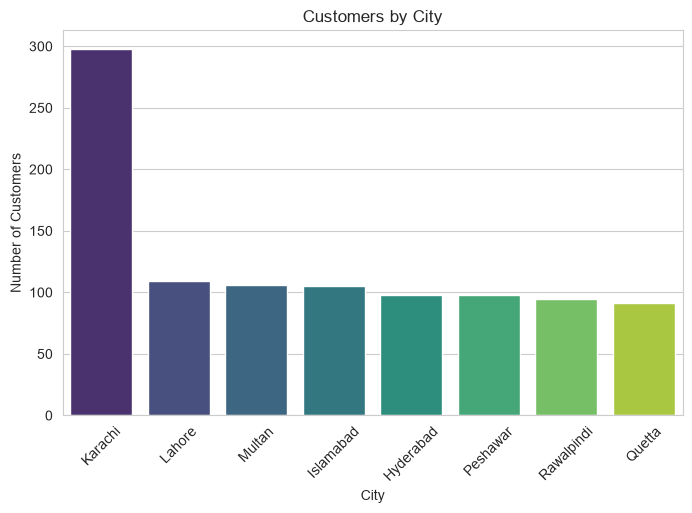

In [43]:
#EDA Step 2 — Customer Analysis

#Let's begin answering business questions about the customers.

## Customer Distribution by City

# This analysis examines how customers are distributed across different cities.

# Understanding customer concentration helps businesses:

# - Identify major markets
# - Allocate marketing budgets
# - Plan logistics and delivery
# - Target future business expansion

# A bar chart is used to compare customer counts across cities.

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# ================= Customer Distribution by City =================

city_counts = (
    customers_clean["city"]
    .value_counts()
)

print("================ Customers by City ================")
print(city_counts)

plt.figure(figsize=(8,5))

sns.barplot(
    x=city_counts.index,
    y=city_counts.values,
    hue=city_counts.index,
    palette="viridis",
    legend=False
)

plt.title("Customers by City")
plt.xlabel("City")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)

plt.show()

# ### Insights

# - Karachi has the highest number of customers (298), making it the company's largest customer market.
# - The remaining cities have relatively similar customer counts, ranging from 91 to 109 customers.
# - Quetta has the fewest customers, indicating potential opportunities for customer acquisition and market expansion.
# - Overall, the customer base is moderately concentrated in Karachi while remaining geographically distributed across other major cities in Pakistan.

# ### Business Recommendation

# - Prioritize marketing campaigns and customer retention strategies in Karachi to maximize revenue.
# - Increase promotional activities in cities with fewer customers to improve market penetration.
# - Maintain a balanced logistics and customer support network across all major cities.

================ Customers by Gender ================
gender
Female     434
Male       425
Unknown    141
Name: count, dtype: int64


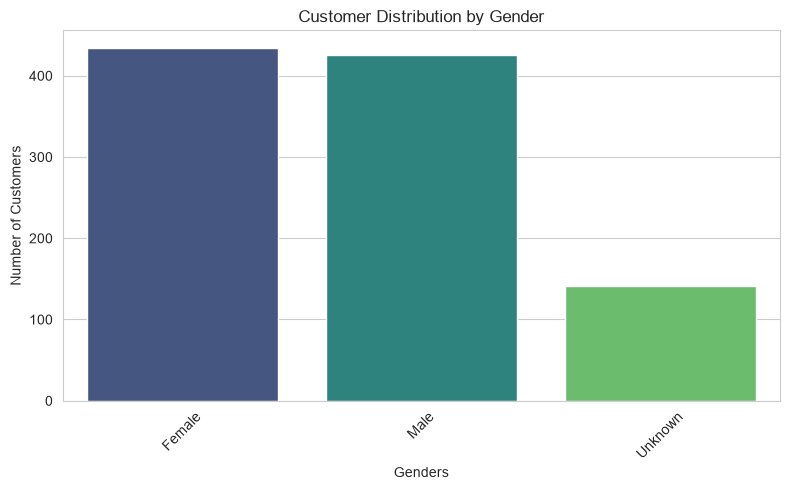

In [44]:
# Next Step (EDA Step 3)

# Now we'll analyze Customer Gender Distribution to answer:

# What percentage of customers are Male, Female, and Unknown?
# Is the customer base balanced?
# What business insights can we derive?

# This is the next logical step in customer profiling before analyzing age and signup trends.

# ================= Customer Distribution by Gender =================

gender_count = (
    customers_clean["gender"]
    .value_counts()
)

print("================ Customers by Gender ================")

print(gender_count)

plt.figure(figsize=(8,5))

sns.barplot(
    x=gender_count.index,
    y=gender_count.values,
    hue=gender_count.index,
    palette="viridis",
    legend=False
)


plt.title("Customer Distribution by Gender")
plt.xlabel("Genders")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

================ Age Statistics ================
count    1000.000000
mean       41.867000
std        13.501541
min        18.000000
25%        30.000000
50%        42.000000
75%        53.000000
max        65.000000
Name: age, dtype: float64


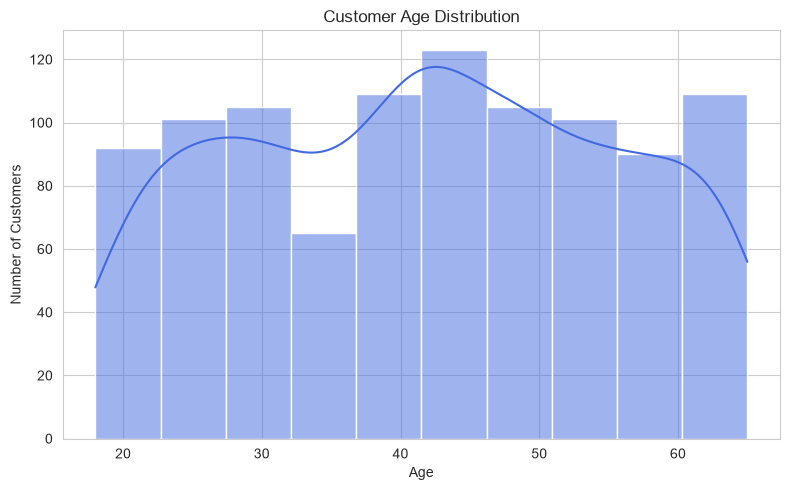

In [45]:
# ================= Customer Age Distribution =================

print("================ Age Statistics ================")

print(customers_clean["age"].describe())

plt.figure(figsize=(8,5))

sns.histplot(
    customers_clean["age"],
    bins=10,
    kde=True,
    color="royalblue"
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.show()

================ Customers by Signup Year ================
signup_date
2022.0    281
2023.0    305
2024.0    296
2025.0     85
Name: count, dtype: int64


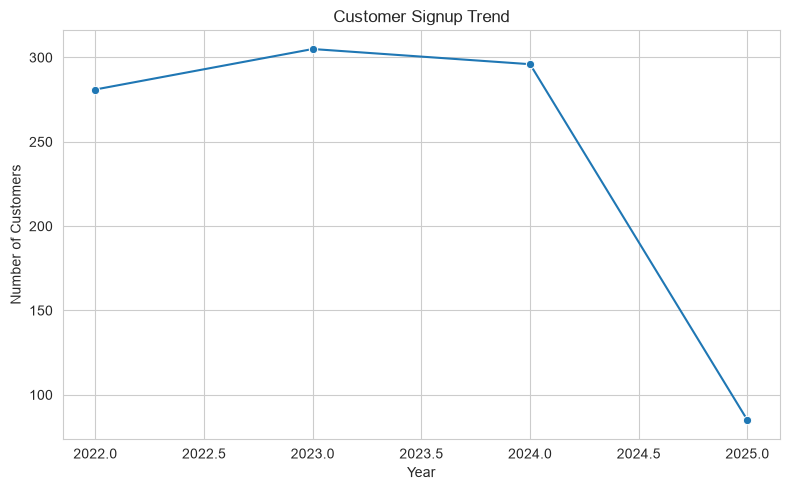

In [46]:
# ================= Customer Signup Trend =================

signup_year = (
    customers_clean["signup_date"]
    .dt.year
    .value_counts()
    .sort_index()
)


print("================ Customers by Signup Year ================")


print(signup_year)

plt.figure(figsize=(8,5))

sns.lineplot(
    x=signup_year.index,
    y=signup_year.values,
    marker="o"
)


plt.title("Customer Signup Trend")
plt.xlabel("Year")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.show()



# Business Insights (after seeing the graph)

# You will answer questions like:

# Which year had the highest signups?
# Which year had the lowest signups?
# Is the business growing?
# Did customer acquisition decline?
# What should management do?
# Why are we doing this?

# A company always wants to know:

# Are new customers increasing?
# Is marketing working?
# Which years need improvement?

# This is a very common KPI in EDA dashboards.


================ Customers by Signup Month ================
signup_date  1.0   2.0   3.0   4.0   5.0   6.0   7.0   8.0   9.0   10.0  11.0  \
signup_date                                                                     
2022.0         28    23    19    23    27    26    21    29    19    23    21   
2023.0         25    19    19    25    28    27    32    25    30    22    27   
2024.0         16    30    29    25    33    12    30    26    24    25    23   
2025.0         23    21    25    16     0     0     0     0     0     0     0   

signup_date  12.0  
signup_date        
2022.0         22  
2023.0         26  
2024.0         23  
2025.0          0  
signup_date
2022-01-01    28
2022-02-01    23
2022-03-01    19
2022-04-01    23
2022-05-01    27
2022-06-01    26
2022-07-01    21
2022-08-01    29
2022-09-01    19
2022-10-01    23
2022-11-01    21
2022-12-01    22
2023-01-01    25
2023-02-01    19
2023-03-01    19
2023-04-01    25
2023-05-01    28
2023-06-01    27
2023-07-01    3

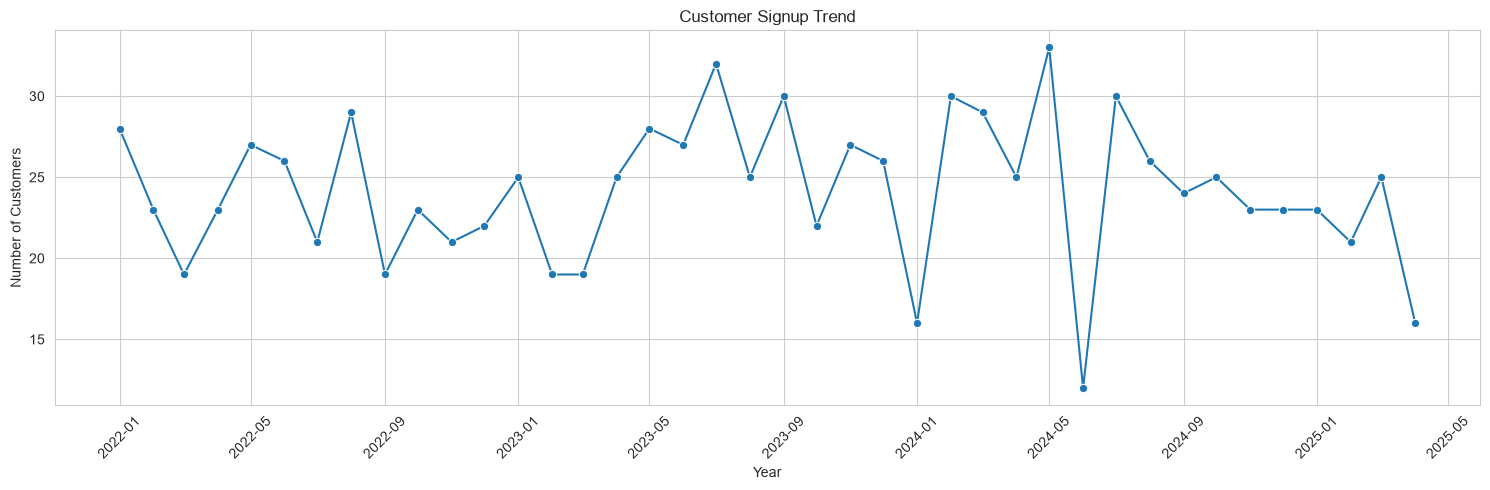

In [47]:
# ================= Customer Signup Trend ( Monthly ) =================

signup_month = (
    customers_clean["signup_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
    .value_counts()
    .sort_index()
)



signup_table = pd.crosstab(
    customers_clean["signup_date"].dt.year,
    customers_clean["signup_date"].dt.month
)


print("================ Customers by Signup Month ================")
print(signup_table)


print(signup_month)

plt.figure(figsize=(15,5))

sns.lineplot(
    x=signup_month.index,
    y=signup_month.values,
    marker="o"
)



plt.title("Customer Signup Trend")
plt.xlabel("Year")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.show()


In [48]:
# ================= Merge Orders with Products =================


orders_products = orders_clean.merge(
    products_clean,
    on="product_id",
    how="left"
)

print(orders_products.head())

  order_id customer_id product_id order_date  quantity payment_method  \
0   O00001       C0720      P0508 2023-10-24       3.0           Cash   
1   O00002       C0485      P0231 2023-04-01       3.0            NaN   
2   O00003       C0519      P0032 2023-04-13       3.0            Cod   
3   O00004       C0101      P0205 2023-07-08       3.0            NaN   
4   O00005       C0711      P0244 2023-11-23       3.0           Card   

  order_status  discount  shipping_cost product_name     category    price  \
0    Delivered      25.0          465.0          NaN          NaN      NaN   
1    Cancelled      25.0          465.0  Product 231        Books  20357.0   
2    Delivered      25.0          465.0   Product 32        Books  32685.0   
3    Cancelled      25.0          465.0  Product 205       Beauty  31807.0   
4    Delivered       2.0          778.0  Product 244  Electronics  22705.0   

      cost     supplier  
0      NaN          NaN  
1   6457.0   Supplier 3  
2   1800.0  Su

================ Orders by Category ================
category
Electronics    621
Fashion        291
Beauty         282
Books          269
Sports         230
Home           227
Name: count, dtype: int64


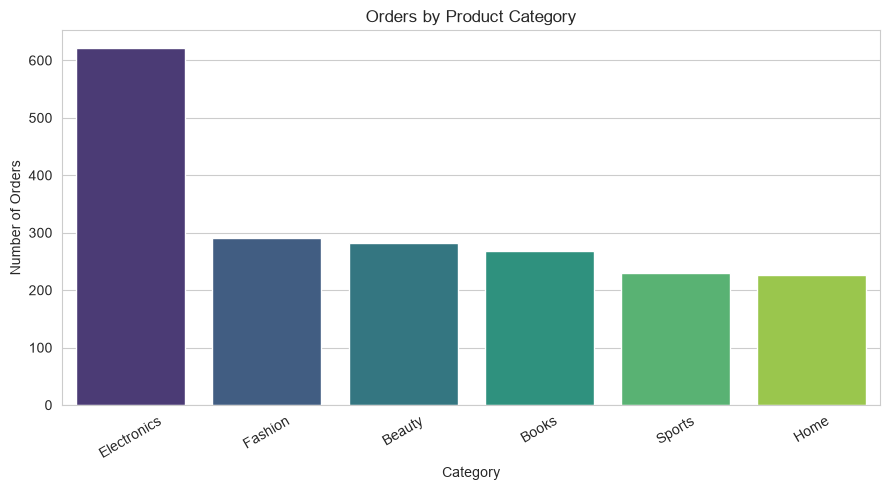

In [49]:
# ================= Orders by Category =================

category_orders = (
    orders_products["category"]
    .value_counts()
)

print("================ Orders by Category ================")

print(category_orders)

plt.figure(figsize=(9,5))

sns.barplot(
    x=category_orders.index,
    y=category_orders.values,
    hue=category_orders.index,
    palette="viridis",
    legend=False
)

plt.title("Orders by Product Category")
plt.xlabel("Category")
plt.ylabel("Number of Orders")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

     price  quantity  discount   revenue
0      NaN       3.0      25.0       NaN
1  20357.0       3.0      25.0  45803.25
2  32685.0       3.0      25.0  73541.25
3  31807.0       3.0      25.0  71565.75
4  22705.0       3.0       2.0  66752.70
================ Revenue by Category ================
category
Electronics    3.491046e+07
Beauty         1.710683e+07
Fashion        1.574839e+07
Books          1.539752e+07
Sports         1.305144e+07
Home           1.089887e+07
Name: revenue, dtype: float64


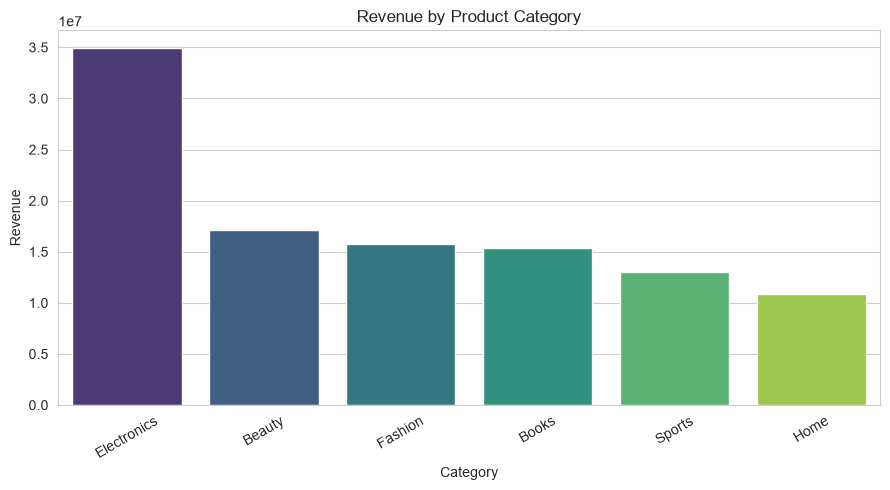

In [50]:
#Create Revenue Column

orders_products["revenue"] = (
    orders_products["price"] *
    orders_products["quantity"] *
    (1 - orders_products["discount"] / 100)
)

print(orders_products[[
    "price",
    "quantity",
    "discount",
    "revenue"
]].head())

#Revenue by Category

category_revenue = (
    orders_products
    .groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("================ Revenue by Category ================")
print(category_revenue)

#Plot

plt.figure(figsize=(9,5))

sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values,
    hue=category_revenue.index,
    palette="viridis",
    legend=False
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

================ Orders by Status ================
order_status
Delivered    1017
Cancelled     496
Pending       487
Name: count, dtype: int64


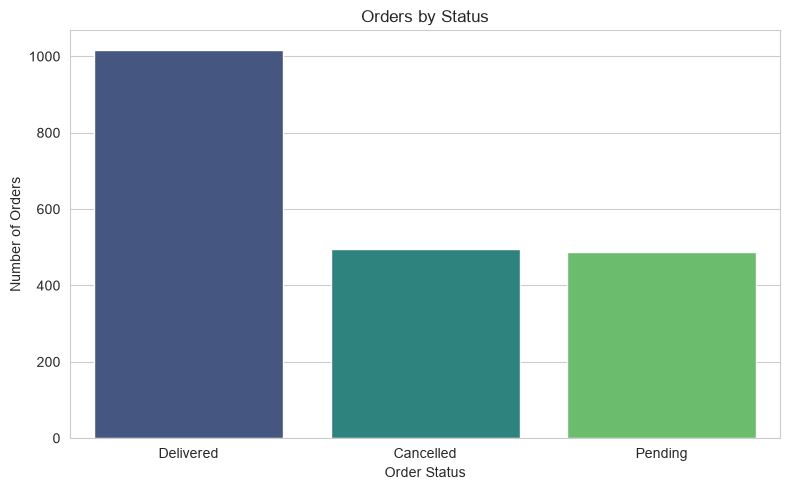

In [51]:
# ================= Orders by Status =================

status_count = (
    orders_clean["order_status"]
    .value_counts()
)

print("================ Orders by Status ================")
print(status_count)

plt.figure(figsize=(8,5))

sns.barplot(
    x=status_count.index,
    y=status_count.values,
    hue=status_count.index,
    palette="viridis",
    legend=False
)

plt.title("Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.tight_layout()

plt.show()

================ Revenue by Order Status ================
order_status
Delivered    5.474629e+07
Cancelled    2.659364e+07
Pending      2.577357e+07
Name: revenue, dtype: float64


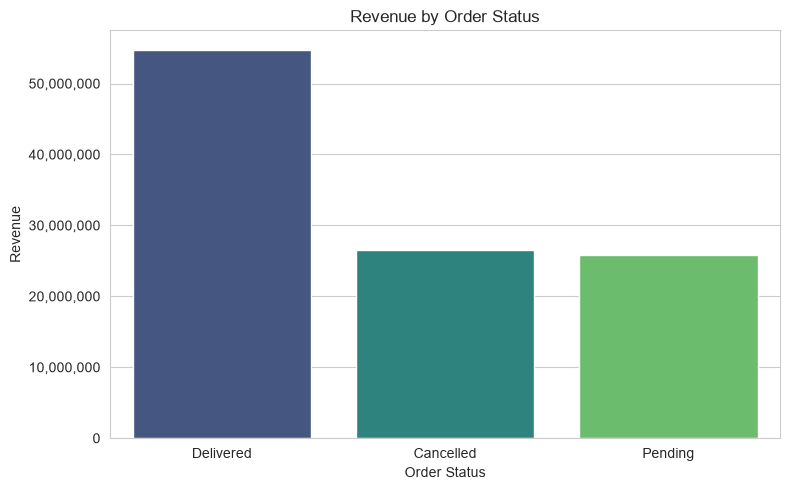

In [52]:
# ================= Revenue by Order Status =================
from matplotlib.ticker import FuncFormatter
status_revenue = (
    orders_products
    .groupby("order_status")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("================ Revenue by Order Status ================")
print(status_revenue)

plt.figure(figsize=(8,5))

sns.barplot(
    x=status_revenue.index,
    y=status_revenue.values,
    hue=status_revenue.index,
    palette="viridis",
    legend=False
)

plt.title("Revenue by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Revenue")
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)
plt.tight_layout()

plt.show()

================ Orders by Payment Method ================
payment_method
Card       448
Cod        401
Cash       395
Unknown    391
Bank       365
Name: count, dtype: int64


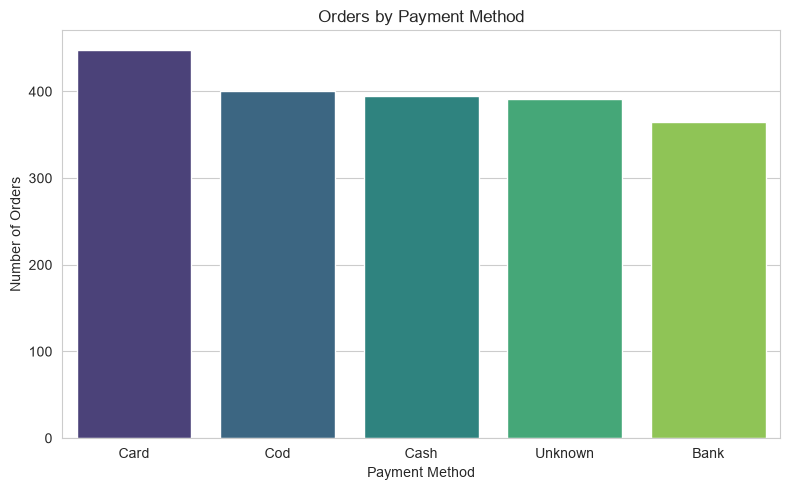

In [53]:
# ================= Payment Method Distribution =================

payment_count = (
    orders_clean["payment_method"]
    .fillna("Unknown")
    .value_counts()
)

print("================ Orders by Payment Method ================")
print(payment_count)

plt.figure(figsize=(8,5))

sns.barplot(
    x=payment_count.index,
    y=payment_count.values,
    hue=payment_count.index,
    palette="viridis",
    legend=False
)

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.tight_layout()

plt.show()

================ Monthly Orders ================
order_date
2023-01-01    97
2023-02-01    75
2023-03-01    96
2023-04-01    85
2023-05-01    72
2023-06-01    78
2023-07-01    95
2023-08-01    78
2023-09-01    96
2023-10-01    86
2023-11-01    81
2023-12-01    87
2024-01-01    79
2024-02-01    87
2024-03-01    76
2024-04-01    88
2024-05-01    94
2024-06-01    78
2024-07-01    96
2024-08-01    78
2024-09-01    84
2024-10-01    76
2024-11-01    73
2024-12-01     3
Name: count, dtype: int64


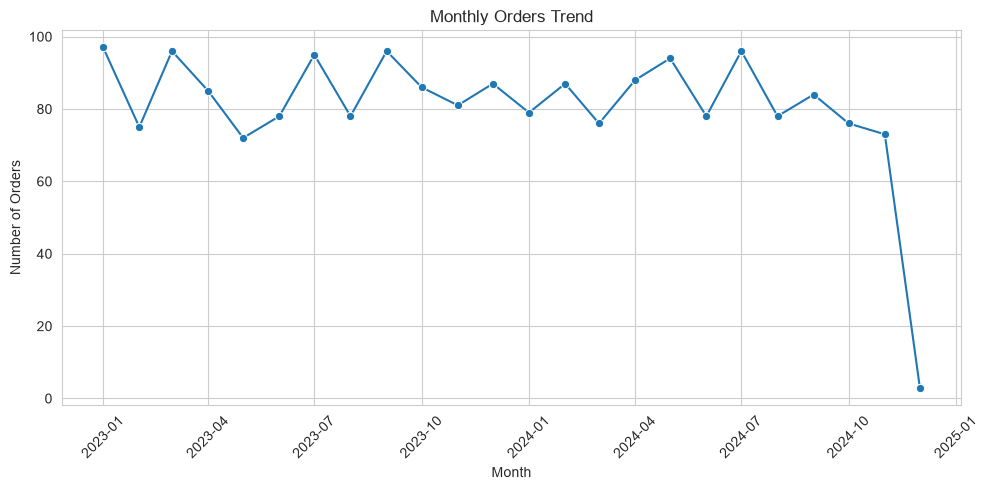

In [54]:
# ================= Monthly Orders Trend =================

monthly_orders = (
    orders_clean["order_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
    .value_counts()
    .sort_index()
)

print("================ Monthly Orders ================")
print(monthly_orders)

plt.figure(figsize=(10,5))

sns.lineplot(
    x=monthly_orders.index,
    y=monthly_orders.values,
    marker="o"
)

plt.title("Monthly Orders Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

================ Monthly Revenue ================
order_date
2023-01-01    4355270.390
2023-02-01    3585861.300
2023-03-01    5080452.530
2023-04-01    4276123.600
2023-05-01    3999939.605
2023-06-01    4331399.820
2023-07-01    4619950.330
2023-08-01    4231273.295
2023-09-01    5453682.310
2023-10-01    5169457.060
2023-11-01    4320746.710
2023-12-01    4421725.230
2024-01-01    4881858.330
2024-02-01    4775335.930
2024-03-01    3920899.160
2024-04-01    5128510.020
2024-05-01    5065144.640
2024-06-01    4429871.455
2024-07-01    5029893.550
2024-08-01    4138729.185
2024-09-01    4848769.115
2024-10-01    3981597.575
2024-11-01    3437281.620
2024-12-01     169028.770
Name: revenue, dtype: float64


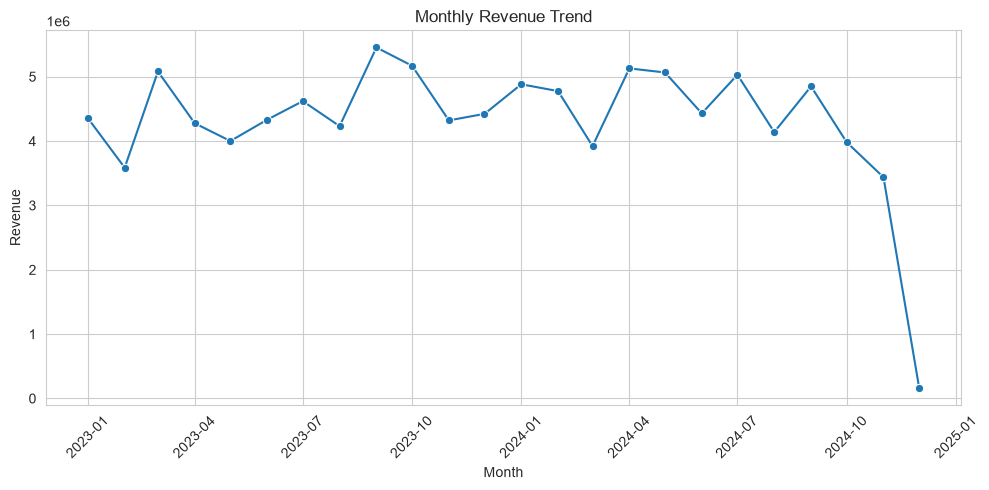

In [55]:
# ================= Monthly Revenue Trend =================

monthly_revenue = (
    orders_products
    .groupby(
        orders_products["order_date"]
        .dt.to_period("M")
        .dt.to_timestamp()
    )["revenue"]
    .sum()
)

print("================ Monthly Revenue ================")
print(monthly_revenue)

plt.figure(figsize=(10,5))

sns.lineplot(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

================ Top 10 Best Selling Products ================
product_name
Product 411    34.0
Product 167    34.0
Product 301    31.0
Product 292    28.0
Product 356    27.0
Product 89     27.0
Product 223    26.0
Product 220    26.0
Product 235    26.0
Product 123    26.0
Name: quantity, dtype: float64


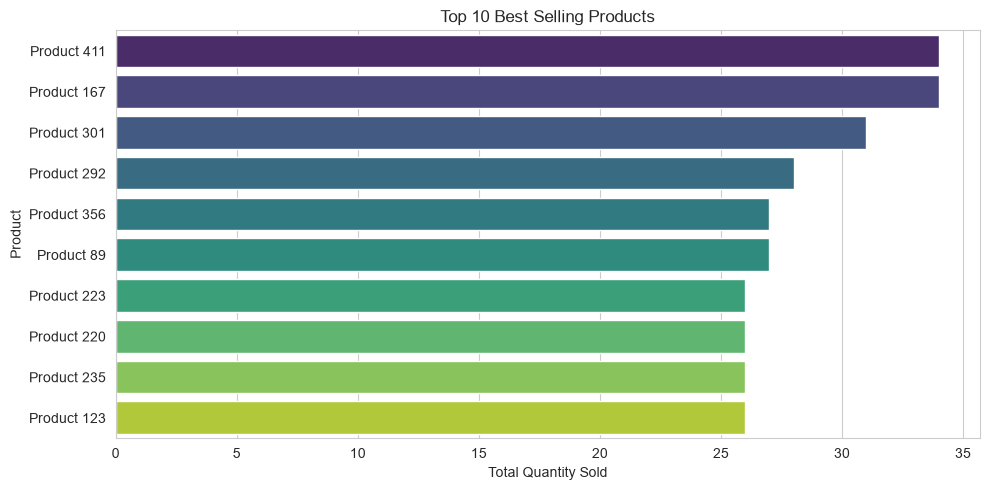

In [56]:
# ================= Top 10 Best Selling Products =================

top_products = (
    orders_products
    .groupby("product_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("================ Top 10 Best Selling Products ================")
print(top_products)

plt.figure(figsize=(10,5))

sns.barplot(
    x=top_products.values,
    y=top_products.index,
    hue=top_products.index,
    palette="viridis",
    legend=False
)

plt.title("Top 10 Best Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()

plt.show()

================ Top 10 Revenue Generating Products ================
product_name
Product 292    952848.40
Product 123    928385.94
Product 308    801408.60
Product 425    772932.00
Product 165    759828.24
Product 223    752105.28
Product 135    684990.93
Product 185    680466.00
Product 261    679760.64
Product 277    674590.80
Name: revenue, dtype: float64


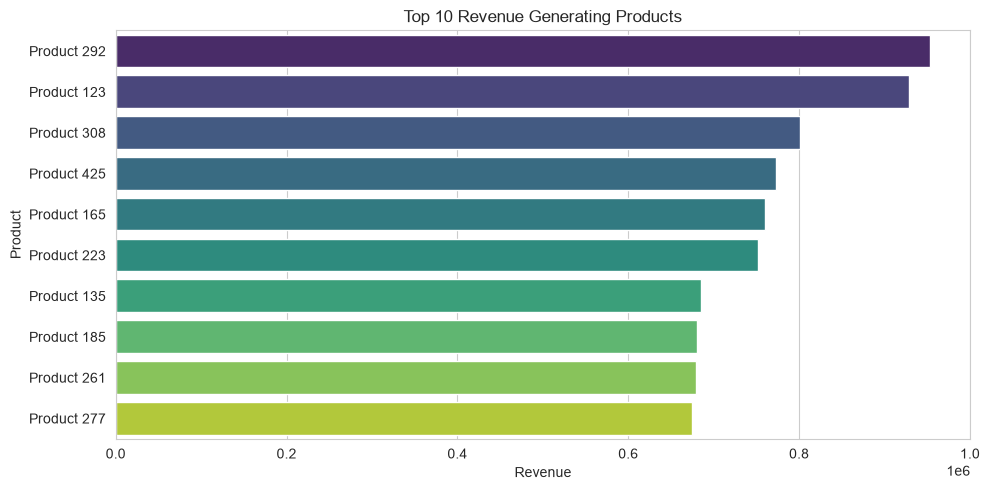

In [57]:
# ================= Top 10 Revenue Generating Products =================

top_revenue_products = (
    orders_products
    .groupby("product_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("================ Top 10 Revenue Generating Products ================")
print(top_revenue_products)

plt.figure(figsize=(10,5))

sns.barplot(
    x=top_revenue_products.values,
    y=top_revenue_products.index,
    hue=top_revenue_products.index,
    palette="viridis",
    legend=False
)

plt.title("Top 10 Revenue Generating Products")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()

plt.show()

================ Top 10 Customers by Revenue ================
customer_id
C0014    618940.68
C0752    512055.69
C0386    491746.08
C0378    482970.75
C0949    464823.83
C0023    447347.91
C0647    443605.50
C0082    427764.78
C0933    416664.00
C0710    390671.52
Name: revenue, dtype: float64


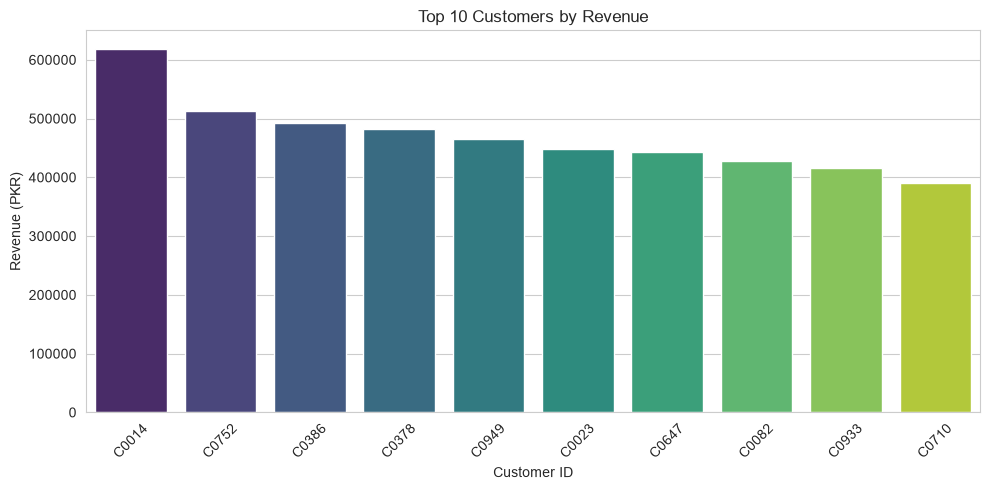

In [58]:
# ================= Top Customers by Revenue =================

customer_revenue = (
    orders_products
    .groupby("customer_id")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("================ Top 10 Customers by Revenue ================")
print(customer_revenue)

plt.figure(figsize=(10,5))

sns.barplot(
    x=customer_revenue.index,
    y=customer_revenue.values,
    hue=customer_revenue.index,
    palette="viridis",
    legend=False
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue (PKR)")

plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


  order_id customer_id product_id order_date  quantity payment_method  \
0   O00001       C0720      P0508 2023-10-24       3.0           Cash   
1   O00002       C0485      P0231 2023-04-01       3.0            NaN   
2   O00003       C0519      P0032 2023-04-13       3.0            Cod   
3   O00004       C0101      P0205 2023-07-08       3.0            NaN   
4   O00005       C0711      P0244 2023-11-23       3.0           Card   

  order_status  discount  shipping_cost product_name     category    price  \
0    Delivered      25.0          465.0          NaN          NaN      NaN   
1    Cancelled      25.0          465.0  Product 231        Books  20357.0   
2    Delivered      25.0          465.0   Product 32        Books  32685.0   
3    Cancelled      25.0          465.0  Product 205       Beauty  31807.0   
4    Delivered       2.0          778.0  Product 244  Electronics  22705.0   

      cost     supplier   revenue       city  
0      NaN          NaN       NaN   Peshawar 

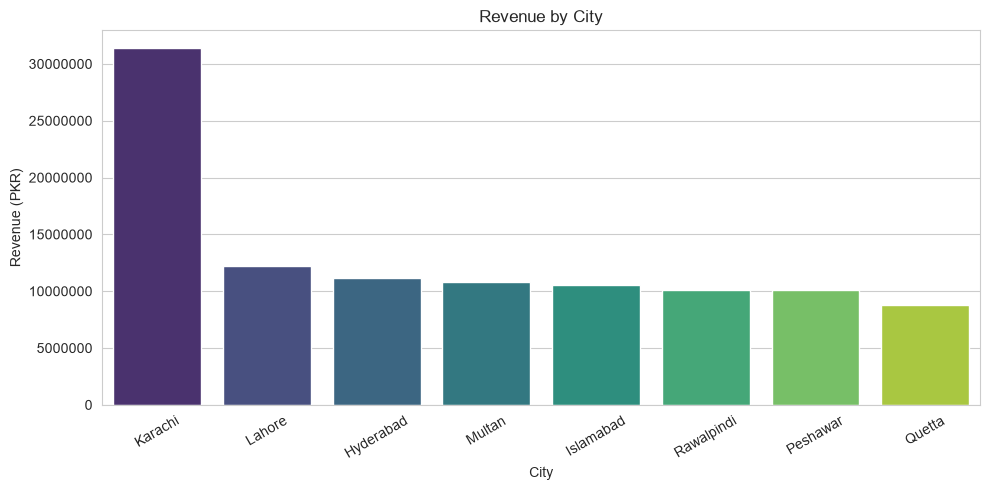

In [59]:
# ================= Merge Customer City =================

orders_full = orders_products.merge(
    customers_clean[["customer_id", "city"]],
    on="customer_id",
    how="left"
)

print(orders_full.head())
# ================= Revenue by City =================

city_revenue = (
    orders_full
    .groupby("city")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("================ Revenue by City ================")
print(city_revenue)

plt.figure(figsize=(10,5))

sns.barplot(
    x=city_revenue.index,
    y=city_revenue.values,
    hue=city_revenue.index,
    palette="viridis",
    legend=False
)

plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue (PKR)")

# Show full numbers instead of scientific notation
plt.ticklabel_format(style="plain", axis="y")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()


================ Revenue by Payment Method ================
payment_method
Card       24033955.37
Cod        21759650.66
Cash       20942885.60
Unknown    20489902.09
Bank       19887104.78
Name: revenue, dtype: float64


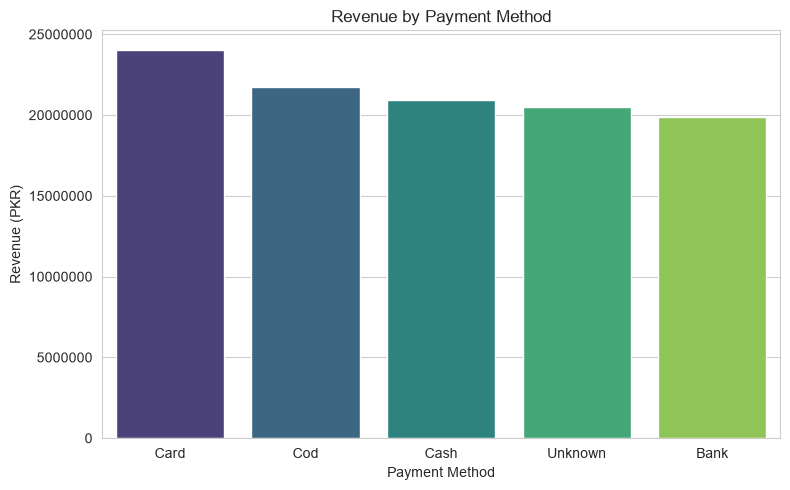

In [60]:
# ================= Revenue by Payment Method =================

payment_revenue = (
    orders_products
    .assign(payment_method=orders_products["payment_method"].fillna("Unknown"))
    .groupby("payment_method")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("================ Revenue by Payment Method ================")
print(payment_revenue)

plt.figure(figsize=(8,5))

sns.barplot(
    x=payment_revenue.index,
    y=payment_revenue.values,
    hue=payment_revenue.index,
    palette="viridis",
    legend=False
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue (PKR)")

# Show full revenue values
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()

plt.show()


     price     cost  quantity  discount    profit
0      NaN      NaN       3.0      25.0       NaN
1  20357.0   6457.0       3.0      25.0  31275.00
2  32685.0   1800.0       3.0      25.0  69491.25
3  31807.0  25984.0       3.0      25.0  13101.75
4  22705.0  10214.0       3.0       2.0  36723.54
================ Profit by Category ================
category
Electronics    1.448709e+07
Books          9.572157e+06
Fashion        7.228161e+06
Beauty         7.205502e+06
Sports         4.541827e+06
Home           4.297090e+06
Name: profit, dtype: float64


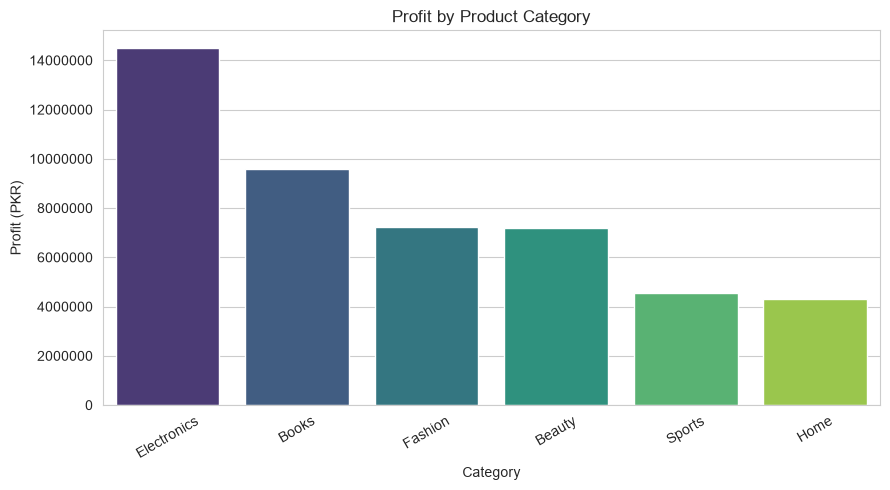

In [61]:
# ================= Create Profit Column =================

orders_products["profit"] = (
    (orders_products["price"] - orders_products["cost"])
    * orders_products["quantity"]
    * (1 - orders_products["discount"] / 100)
)

print(
    orders_products[
        ["price", "cost", "quantity", "discount", "profit"]
    ].head()
)

# ================= Profit by Category =================

category_profit = (
    orders_products
    .groupby("category")["profit"]
    .sum()
    .sort_values(ascending=False)
)

print("================ Profit by Category ================")
print(category_profit)

plt.figure(figsize=(9,5))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values,
    hue=category_profit.index,
    palette="viridis",
    legend=False
)

plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit (PKR)")

# Display full numbers on the y-axis
plt.ticklabel_format(style="plain", axis="y")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

In [62]:
# ================= Phase 3 — Feature Engineering =================
# This keeps our workflow organized:
# Step 1 — Create Working Copy

orders_features = orders_products.copy()

print("============== Orders features =================")

print("Shap: ",orders_products.shape)

print("\nColumn: ")
print(orders_products.columns.tolist())

print("\nFirst Five Rows: ")
print(orders_products.head())

print("================ Existing Numerical Features ================")

print(
    orders_features[
        ["price", "cost", "quantity", "discount", "shipping_cost", "revenue"]
    ].head()
)

print("\n================ Data Types ================")

print(
    orders_features[
        ["price", "cost", "quantity", "discount", "shipping_cost", "revenue"]
    ].dtypes
)

============== Orders features =================
Shap:  (2000, 16)

Column: 
['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'payment_method', 'order_status', 'discount', 'shipping_cost', 'product_name', 'category', 'price', 'cost', 'supplier', 'revenue', 'profit']

First Five Rows: 
  order_id customer_id product_id order_date  quantity payment_method  \
0   O00001       C0720      P0508 2023-10-24       3.0           Cash   
1   O00002       C0485      P0231 2023-04-01       3.0            NaN   
2   O00003       C0519      P0032 2023-04-13       3.0            Cod   
3   O00004       C0101      P0205 2023-07-08       3.0            NaN   
4   O00005       C0711      P0244 2023-11-23       3.0           Card   

  order_status  discount  shipping_cost product_name     category    price  \
0    Delivered      25.0          465.0          NaN          NaN      NaN   
1    Cancelled      25.0          465.0  Product 231        Books  20357.0   
2    Delivered      25

In [63]:
# ================= Step 2 — Order-Level Features =================

print("================ Creating Order-Level Features ================")


orders_features["discount_amount"] = (
    orders_features["price"] *
    orders_features["quantity"]*
    ( orders_features["discount"] / 100)
)


orders_features["order_year"] = (
    orders_features["order_date"].dt.year
)


orders_features["order_month"] = (
    orders_features["order_date"].dt.month
)

orders_features["order_quarter"] = (
    orders_features["order_date"].dt.quarter
)

orders_features["order_weekday"] = (
    orders_features["order_date"].dt.day_name()
)

print("\n Features Created Successfully !! ")
print("\n Columns : ")

print(
    orders_features[
        [
            "order_id",
            "price",
            "quantity",
            "discount",
            "discount_amount",
            "order_year",
            "order_month",
            "order_quarter",
            "order_weekday"
        ]
    ].head()
)

================ Creating Order-Level Features ================

 Features Created Successfully !! 

 Columns : 
  order_id    price  quantity  discount  discount_amount  order_year  \
0   O00001      NaN       3.0      25.0              NaN      2023.0   
1   O00002  20357.0       3.0      25.0         15267.75      2023.0   
2   O00003  32685.0       3.0      25.0         24513.75      2023.0   
3   O00004  31807.0       3.0      25.0         23855.25      2023.0   
4   O00005  22705.0       3.0       2.0          1362.30      2023.0   

   order_month  order_quarter order_weekday  
0         10.0            4.0       Tuesday  
1          4.0            2.0      Saturday  
2          4.0            2.0      Thursday  
3          7.0            3.0      Saturday  
4         11.0            4.0      Thursday  


In [64]:
# ================= Profit Margin =================


orders_features["profit_margin"] = (
    (orders_features["profit"]/
    orders_features["revenue"])*
    100
)


print("================= Profit Margin =================")


print(
    orders_features[
        [

        "order_id",
        "revenue",
        "profit",
        "profit_margin"
        ]
    ].head()
)

================= Profit Margin =================
  order_id   revenue    profit  profit_margin
0   O00001       NaN       NaN            NaN
1   O00002  45803.25  31275.00      68.281181
2   O00003  73541.25  69491.25      94.492887
3   O00004  71565.75  13101.75      18.307291
4   O00005  66752.70  36723.54      55.014314


In [65]:
# Create
#   ↓
# Inspect
#   ↓
# Validate
#   ↓
#  Use


print("\n================ Profit Margin Statistics ================")

print(
    orders_features["profit_margin"].describe()
)

print("\n================ Invalid Profit Margins ================")

print(
    orders_features.loc[
        (orders_features["profit_margin"] < 0) |
        (orders_features["profit_margin"] > 100),
        [
            "order_id",
            "revenue",
            "profit",
            "profit_margin"
        ]
    ]
)


================ Profit Margin Statistics ================
count     1920.000000
mean       444.839731
std       3461.376195
min      -5688.669951
25%         19.816146
50%         45.812780
75%         72.268688
max      42075.000000
Name: profit_margin, dtype: float64

================ Invalid Profit Margins ================
     order_id   revenue    profit  profit_margin
25     O00026   -375.00 -38677.50   10314.000000
31     O00032   -225.00  -4527.00    2012.000000
64     O00065   9070.50  -9838.50    -108.467008
88     O00089   1050.00 -10397.10    -990.200000
112    O00113   -225.00 -23206.50   10314.000000
...       ...       ...       ...            ...
1897   O01898   1125.00 -13772.25   -1224.200000
1923   O01924   -225.00 -45443.25   20197.000000
1969   O01970   1125.00 -13772.25   -1224.200000
1975   O01976   -225.00 -22956.75   10203.000000
1986   O01987  11363.52  -8378.16     -73.728563

[92 rows x 4 columns]


In [66]:
# ================= Investigate Abnormal Profit Margins =================

print("================ Abnormal Profit Margin Orders ================")

abnormal_margin = orders_features[
    (orders_features["profit_margin"] < 0) |
    (orders_features["profit_margin"] > 100)
]

print(
    abnormal_margin[
        [
            "order_id",
            "price",
            "cost",
            "quantity",
            "discount",
            "discount_amount",
            "revenue",
            "profit",
            "profit_margin"
        ]
    ].head(20)
)

print("\n================ Negative Revenue ================")

print(
    orders_features.loc[
        orders_features["revenue"] < 0,
        [
            "order_id",
            "price",
            "quantity",
            "discount",
            "revenue",
            "profit"
        ]
    ]
)

print("\nNumber of Negative Revenue Orders:")

print(
    (orders_features["revenue"] < 0).sum()
)

================ Abnormal Profit Margin Orders ================
    order_id   price     cost  quantity  discount  discount_amount   revenue  \
25    O00026  -100.0  10214.0       5.0      25.0          -125.00   -375.00   
31    O00032  -100.0   1912.0       3.0      25.0           -75.00   -225.00   
64    O00065  6047.0  12606.0       2.0      25.0          3023.50   9070.50   
88    O00089   500.0   5451.0       3.0      30.0           450.00   1050.00   
112   O00113  -100.0  10214.0       3.0      25.0           -75.00   -225.00   
155   O00156  -100.0  12215.0       4.0       8.0           -32.00   -368.00   
160   O00161  6764.0  11751.0       3.0      25.0          5073.00  15219.00   
165   O00166  -100.0  12215.0       3.0       8.0           -24.00   -276.00   
175   O00176  -100.0  37343.0       3.0      25.0           -75.00   -225.00   
186   O00187  8490.0  11751.0       1.0      19.0          1613.10   6876.90   
200   O00201  -100.0  41975.0       3.0      25.0       

In [67]:
# ================= Investigate Invalid Prices =================

print("================ Price Information ================")

print("Data Type:")
print(orders_products["price"].dtype)

print("\nMissing Values:")
print(orders_products["price"].isna().sum())

print("\nSummary Statistics:")
print(orders_products["price"].describe())

print("\nMinimum Price:")
print(orders_products["price"].min())

print("\nMaximum Price:")
print(orders_products["price"].max())


print("\n================ Invalid Prices (<=0) ================")

invalid_prices = orders_products.loc[
    orders_products["price"] <= 0,
    [
        "order_id",
        "product_id",
        "product_name",
        "category",
        "price",
        "cost",
        "quantity",
        "discount"
    ]
]

print(invalid_prices)

print("\nNumber of Invalid Prices:")
print((orders_products["price"] <= 0).sum())

================ Price Information ================
Data Type:
float64

Missing Values:
80

Summary Statistics:
count     1920.000000
mean     24875.548438
std      14186.042990
min       -100.000000
25%      12789.000000
50%      24953.000000
75%      36686.500000
max      49864.000000
Name: price, dtype: float64

Minimum Price:
-100.0

Maximum Price:
49864.0

================ Invalid Prices (<=0) ================
     order_id product_id product_name     category  price     cost  quantity  \
25     O00026      P0356  Product 356  Electronics -100.0  10214.0       5.0   
31     O00032      P0384  Product 384        Books -100.0   1912.0       3.0   
112    O00113      P0356  Product 356  Electronics -100.0  10214.0       3.0   
155    O00156      P0421  Product 421       Beauty -100.0  12215.0       4.0   
165    O00166      P0421  Product 421       Beauty -100.0  12215.0       3.0   
175    O00176      P0338  Product 338  Electronics -100.0  37343.0       3.0   
200    O00201      P0

In [68]:
# ================= Clean Order Price =================

print("================ Price Cleaning ================")

# Count invalid prices
invalid_price = orders_products["price"].isna() | (orders_products["price"] <= 0)

print("Missing or Invalid Prices Before:", invalid_price.sum())


# Create product price lookup
product_price_lookup = (
    products_clean
    .set_index("product_id")["price"]
)


# Recover missing and invalid prices using product_id
orders_products.loc[invalid_price, "price"] = (
    orders_products.loc[invalid_price, "product_id"]
    .map(product_price_lookup)
)


print("\nMissing or Invalid Prices After:")

print(
    orders_products["price"].isna().sum()
    + (orders_products["price"] <= 0).sum()
)


print("\nPrice Statistics After Cleaning:")
print(orders_products["price"].describe())

================ Price Cleaning ================
Missing or Invalid Prices Before: 128

Missing or Invalid Prices After:
128

Price Statistics After Cleaning:
count     1920.000000
mean     24875.548438
std      14186.042990
min       -100.000000
25%      12789.000000
50%      24953.000000
75%      36686.500000
max      49864.000000
Name: price, dtype: float64


In [69]:
print("\n================ Verification ================")

print("Missing Prices:")
print(orders_products["price"].isna().sum())

print("\nInvalid Prices (<= 0):")
print((orders_products["price"] <= 0).sum())

print("\nMinimum Price:")
print(orders_products["price"].min())

print("\nMaximum Price:")
print(orders_products["price"].max())


================ Verification ================
Missing Prices:
80

Invalid Prices (<= 0):
48

Minimum Price:
-100.0

Maximum Price:
49864.0


In [70]:
# ================= Investigate Product ID Matching =================

print("================ Product ID Data Types ================")

print("Orders Product ID:")
print(orders_products["product_id"].dtype)

print("\nProducts Product ID:")
print(products_clean["product_id"].dtype)


print("\n================ Sample Product IDs ================")

print("Orders:")
print(orders_products["product_id"].head(10).tolist())

print("\nProducts:")
print(products_clean["product_id"].head(10).tolist())


print("\n================ Matching Product IDs ================")

matching_ids = orders_products["product_id"].isin(
    products_clean["product_id"]
)

print("Matching IDs:")
print(matching_ids.sum())

print("Non-Matching IDs:")
print((~matching_ids).sum())


print("\n================ Invalid Price Product IDs ================")

invalid_price = (
    orders_products["price"].isna() |
    (orders_products["price"] <= 0)
)

print(
    orders_products.loc[
        invalid_price,
        ["product_id", "price"]
    ].head(20)
)

================ Product ID Data Types ================
Orders Product ID:
str

Products Product ID:
str

================ Sample Product IDs ================
Orders:
['P0508', 'P0231', 'P0032', 'P0205', 'P0244', 'P0168', 'P0047', 'P0101', 'P0319', 'P0014']

Products:
['P0001', 'P0002', 'P0003', 'P0004', 'P0005', 'P0006', 'P0007', 'P0008', 'P0009', 'P0010']

================ Matching Product IDs ================
Matching IDs:
1920
Non-Matching IDs:
80

================ Invalid Price Product IDs ================
    product_id  price
0        P0508    NaN
25       P0356 -100.0
30       P0503    NaN
31       P0384 -100.0
56       P0509    NaN
71       P0517    NaN
79       P0512    NaN
95       P0508    NaN
112      P0356 -100.0
135      P0517    NaN
155      P0421 -100.0
165      P0421 -100.0
175      P0338 -100.0
200      P0132 -100.0
219      P0132 -100.0
233      P0511    NaN
255      P0514    NaN
259      P0421 -100.0
283      P0518    NaN
303      P0188 -100.0


In [71]:
# ================= Recover Invalid Prices =================

invalid_price = orders_products["price"] <= 0

print("================ Invalid Prices Before ================")
print(invalid_price.sum())


# Product price lookup
product_price_lookup = (
    products_clean
    .set_index("product_id")["price"]
)


# Recover invalid prices from products_clean
orders_products.loc[invalid_price, "price"] = (
    orders_products.loc[invalid_price, "product_id"]
    .map(product_price_lookup)
)


print("\n================ Verification ================")

print("Invalid Prices After:")
print(
    (orders_products["price"] <= 0).sum()
)

print("\nMissing Prices:")
print(
    orders_products["price"].isna().sum()
)

print("\nMinimum Price:")
print(
    orders_products["price"].min()
)

# ================= Investigate Missing Product IDs =================

missing_price = orders_products["price"].isna()

missing_product_ids = (
    orders_products.loc[
        missing_price,
        "product_id"
    ]
    .value_counts()
)

print("================ Missing Price Product IDs ================")

print(missing_product_ids)

print("\nNumber of Unique Missing Product IDs:")
print(missing_product_ids.nunique())

print("\nTotal Orders with Missing Prices:")
print(missing_price.sum())

================ Invalid Prices Before ================
48

================ Verification ================
Invalid Prices After:
48

Missing Prices:
80

Minimum Price:
-100.0
================ Missing Price Product IDs ================
product_id
P0505    8
P0509    7
P0515    7
P0507    6
P0508    5
P0517    5
P0514    5
P0510    5
P0511    4
P0516    4
P0502    4
P0503    3
P0512    3
P0518    3
P0519    3
P0506    2
P0501    2
P0520    2
P0504    1
P0513    1
Name: count, dtype: int64

Number of Unique Missing Product IDs:
8

Total Orders with Missing Prices:
80


In [72]:
# ================= Investigate Missing Products =================

missing_product_ids = (
    orders_products.loc[
        orders_products["price"].isna(),
        "product_id"
    ].unique()
)

print("================ Missing Products in Orders ================")

print(missing_product_ids)

print("\nNumber of Missing Product IDs:")
print(len(missing_product_ids))


print("\n================ Check Products Dataset ================")

print(
    products_clean[
        products_clean["product_id"].isin(missing_product_ids)
    ]
)


print("\n================ Orders for Missing Products ================")

print(
    orders_products.loc[
        orders_products["product_id"].isin(missing_product_ids),
        [
            "order_id",
            "product_id",
            "product_name",
            "category",
            "price",
            "cost",
            "quantity",
            "discount"
        ]
    ].head(30)
)

================ Missing Products in Orders ================
<StringArray>
['P0508', 'P0503', 'P0509', 'P0517', 'P0512', 'P0511', 'P0514', 'P0518',
 'P0516', 'P0507', 'P0515', 'P0519', 'P0510', 'P0505', 'P0504', 'P0502',
 'P0506', 'P0501', 'P0520', 'P0513']
Length: 20, dtype: str

Number of Missing Product IDs:
20

================ Check Products Dataset ================
Empty DataFrame
Columns: [product_id, product_name, category, price, cost, supplier]
Index: []

================ Orders for Missing Products ================
    order_id product_id product_name category  price  cost  quantity  discount
0     O00001      P0508          NaN      NaN    NaN   NaN       3.0      25.0
30    O00031      P0503          NaN      NaN    NaN   NaN       3.0       4.0
56    O00057      P0509          NaN      NaN    NaN   NaN       2.0      16.0
71    O00072      P0517          NaN      NaN    NaN   NaN       3.0      25.0
79    O00080      P0512          NaN      NaN    NaN   NaN       3.0     

In [73]:
# ================= Check Product Price Lookup =================

product_price_lookup = (
    products_clean
    .set_index("product_id")["price"]
)

print("P0356 price:")
print(product_price_lookup.get("P0356"))

print("\nP0384 price:")
print(product_price_lookup.get("P0384"))

print("\nP0421 price:")
print(product_price_lookup.get("P0421"))

print("\nCurrent prices in orders:")
print(
    orders_products.loc[
        orders_products["product_id"].isin(
            ["P0356", "P0384", "P0421"]
        ),
        ["product_id", "price"]
    ].head(20)
)

P0356 price:
-100.0

P0384 price:
-100.0

P0421 price:
-100.0

Current prices in orders:
     product_id  price
25        P0356 -100.0
31        P0384 -100.0
112       P0356 -100.0
155       P0421 -100.0
165       P0421 -100.0
259       P0421 -100.0
480       P0356 -100.0
568       P0421 -100.0
674       P0384 -100.0
781       P0421 -100.0
863       P0356 -100.0
1448      P0421 -100.0
1563      P0356 -100.0
1650      P0356 -100.0
1702      P0356 -100.0
1742      P0384 -100.0


In [74]:
# ================= Investigate Invalid Product Prices =================

invalid_product_ids = (
    products_clean.loc[
        products_clean["price"] <= 0,
        "product_id"
    ]
)

print("================ Products with Invalid Prices ================")

print(
    products_clean[
        products_clean["product_id"].isin(invalid_product_ids)
    ]
)

================ Products with Invalid Prices ================
    product_id product_name     category  price     cost     supplier
119      P0120  Product 120      Fashion -100.0  29308.0  Supplier 11
131      P0132  Product 132  Electronics -100.0  41975.0  Supplier 17
155      P0156  Product 156        Books -100.0   4857.0   Supplier 1
187      P0188  Product 188  Electronics -100.0  37518.0   Supplier 6
242      P0243  Product 243       Sports -100.0  20097.0   Supplier 9
337      P0338  Product 338  Electronics -100.0  37343.0  Supplier 13
355      P0356  Product 356  Electronics -100.0  10214.0  Supplier 16
383      P0384  Product 384        Books -100.0   1912.0  Supplier 12
398      P0399  Product 399      Fashion -100.0  13482.0  Supplier 10
420      P0421  Product 421       Beauty -100.0  12215.0  Supplier 11
486      P0487  Product 487         Home -100.0  10103.0  Supplier 11


In [75]:
# ================= Convert Invalid Prices to Missing =================

orders_products.loc[
    orders_products["price"] <= 0,
    "price"
] = pd.NA

print("================ Price Verification ================")

print("Missing Prices:")
print(orders_products["price"].isna().sum())

print("Invalid Prices:")
print((orders_products["price"] <= 0).sum())

# ================= Price Quality Flag =================

orders_products["price_available"] = (
    orders_products["price"].notna()
)

print(
    orders_products["price_available"].value_counts()
)

================ Price Verification ================
Missing Prices:
128
Invalid Prices:
0
price_available
True     1872
False     128
Name: count, dtype: int64


In [76]:
# ================= Recalculate Financial Features =================

# Revenue
orders_products["revenue"] = (
    orders_products["price"]
    * orders_products["quantity"]
    * (1 - orders_products["discount"] / 100)
)

# Profit
orders_products["profit"] = (
    orders_products["revenue"]
    - (orders_products["cost"] * orders_products["quantity"])
)

print("================ Financial Features Recalculated ================")

print(
    orders_products[
        [
            "order_id",
            "price",
            "quantity",
            "discount",
            "cost",
            "revenue",
            "profit"
        ]
    ].head()
)

# ================= Profit Margin =================

orders_products["profit_margin"] = (
    orders_products["profit"]
    / orders_products["revenue"]
) * 100

print("================ Profit Margin Statistics ================")

print(
    orders_products["profit_margin"].describe()
)

================ Financial Features Recalculated ================
  order_id    price  quantity  discount     cost   revenue    profit
0   O00001      NaN       3.0      25.0      NaN       NaN       NaN
1   O00002  20357.0       3.0      25.0   6457.0  45803.25  26432.25
2   O00003  32685.0       3.0      25.0   1800.0  73541.25  68141.25
3   O00004  31807.0       3.0      25.0  25984.0  71565.75  -6386.25
4   O00005  22705.0       3.0       2.0  10214.0  66752.70  36110.70
================ Profit Margin Statistics ================
count    1872.000000
mean      -23.732369
std       527.825721
min     -8539.805897
25%        -7.257991
50%        25.438148
75%        61.611926
max        99.621361
Name: profit_margin, dtype: float64


In [77]:
# ================= Investigate Extreme Profit Margins =================

extreme_margin = (
    orders_products[
        orders_products["profit_margin"] < -100
    ][
        [
            "order_id",
            "product_id",
            "price",
            "cost",
            "quantity",
            "discount",
            "revenue",
            "profit",
            "profit_margin"
        ]
    ]
    .sort_values("profit_margin")
)

print("================ Extreme Profit Margin Orders ================")

print(extreme_margin.head(20))

print("\nNumber of Extreme Margin Orders:")
print(len(extreme_margin))


================ Extreme Profit Margin Orders ================
     order_id product_id  price     cost  quantity  discount  revenue  \
763    O00764      P0157  203.0  11751.0       3.0      33.0   408.03   
709    O00710      P0157  203.0  11751.0       3.0      25.0   456.75   
1772   O01773      P0157  203.0  11751.0       1.0      25.0   152.25   
1176   O01177      P0157  203.0  11751.0       3.0      25.0   456.75   
223    O00224      P0157  203.0  11751.0       3.0      21.0   481.11   
366    O00367      P0157  203.0  11751.0       1.0       3.0   196.91   
943    O00944      P0406  500.0  21782.0       3.0      25.0  1125.00   
1012   O01013      P0406  500.0  21782.0       3.0      25.0  1125.00   
1229   O01230      P0406  500.0  21782.0       3.0      25.0  1125.00   
680    O00681      P0035  500.0  16479.0       2.0      38.0   620.00   
925    O00926      P0035  500.0  16479.0       3.0      21.0  1185.00   
988    O00989      P0008  500.0  11908.0       3.0      25.0 

In [78]:
# ================= Suspicious Price vs Cost =================

suspicious_prices = (
    orders_products[
        (orders_products["price"].notna()) &
        (orders_products["cost"].notna()) &
        (orders_products["price"] < orders_products["cost"])
    ][
        [
            "product_id",
            "product_name",
            "category",
            "price",
            "cost"
        ]
    ]
    .drop_duplicates()
    .sort_values("price")
)

print("================ Products Where Price < Cost ================")

print(suspicious_prices)
print("\nNumber of Suspicious Products:")
print(suspicious_prices["product_id"].nunique())

print("\nNumber of Suspicious Orders:")
print(
    (
        (orders_products["price"].notna()) &
        (orders_products["cost"].notna()) &
        (orders_products["price"] < orders_products["cost"])
    ).sum()
)

================ Products Where Price < Cost ================
     product_id product_name     category   price     cost
223       P0157  Product 157         Home   203.0  11751.0
88        P0415  Product 415      Fashion   500.0   5451.0
680       P0035   Product 35  Electronics   500.0  16479.0
705       P0294  Product 294  Electronics   500.0   6621.0
779       P0008    Product 8       Sports   500.0  11908.0
943       P0406  Product 406       Sports   500.0  21782.0
295       P0330  Product 330       Beauty  2767.0  12792.0
1222      P0030   Product 30      Fashion  4718.0  10224.5
64        P0012   Product 12       Sports  6047.0  12606.0
160       P0496  Product 496         Home  6764.0  11751.0
186       P0154  Product 154         Home  8490.0  11751.0
321       P0051   Product 51      Fashion  9238.0  10224.5

Number of Suspicious Products:
12

Number of Suspicious Orders:
44


In [79]:
# ================= Customer-Level Features =================

customer_features = (
    orders_products
    .groupby("customer_id")
    .agg(
        total_orders=("order_id" , "nunique"),
        total_quantity=("quantity","sum"),
        total_revenue=("revenue" , "sum"),
        total_profit=("profit" , "sum"),
        avg_order_value=("revenue" , "mean"),
        avg_discount=("discount","mean"),
        avg_quantity_per_order=("quantity" , "mean"),
        first_order_date=("order_date" ,"min"),
        last_order_date=("order_date" , "max"),

    )
    .reset_index()
)


print("================ Customer-Level Features ================")


print(customer_features.head())

print("\n Shape : " , customer_features.shape)

================ Customer-Level Features ================
  customer_id  total_orders  total_quantity  total_revenue  total_profit  \
0       C0001             1             3.0       40356.00      19395.00   
1       C0002             2            10.0      179361.85      34696.85   
2       C0003             3             9.0      108420.75      50160.75   
3       C0006             2             4.0       42420.90      -3885.10   
4       C0007             2             6.0       94931.40      23210.40   

   avg_order_value  avg_discount  avg_quantity_per_order first_order_date  \
0        40356.000          25.0                     3.0       2024-04-08   
1        89680.925          36.5                     5.0       2024-02-20   
2        36140.250          25.0                     3.0       2023-03-25   
3        21210.450          27.5                     2.0       2023-12-08   
4        94931.400          41.0                     3.0       2023-06-23   

  last_order_date  
0 

In [80]:
# ================= Customer Lifetime =================

customer_features["customer_lifetime_days"] = (
    customer_features["last_order_date"] 
    - customer_features["first_order_date"]
).dt.days


print("================= Customer Lifetime =================")


print(
    customer_features[
        [
            "customer_id",
            "first_order_date",
            "last_order_date",
            "customer_lifetime_days",

        ]
    ].head()
)

================= Customer Lifetime =================
  customer_id first_order_date last_order_date  customer_lifetime_days
0       C0001       2024-04-08      2024-04-08                     0.0
1       C0002       2024-02-20      2024-08-26                   188.0
2       C0003       2023-03-25      2023-08-22                   150.0
3       C0006       2023-12-08      2024-07-06                   211.0
4       C0007       2023-06-23      2023-09-10                    79.0


In [81]:
# ================= Customer Profit Margin =================

customer_features["profit_margin"] = (
    customer_features["total_profit"]
    / customer_features["total_revenue"]
    * 100
)

print("================ Customer Profit Margin ================")

print(
    customer_features[
        [
            "customer_id",
            "total_revenue",
            "total_profit",
            "profit_margin"
        ]
    ].head()
)

================ Customer Profit Margin ================
  customer_id  total_revenue  total_profit  profit_margin
0       C0001       40356.00      19395.00      48.059768
1       C0002      179361.85      34696.85      19.344610
2       C0003      108420.75      50160.75      46.264899
3       C0006       42420.90      -3885.10      -9.158457
4       C0007       94931.40      23210.40      24.449655


In [82]:
print("================ Customer Feature Statistics ================")

print(customer_features.describe())

print("================ Missing Customer Features ================")

print(customer_features.isna().sum())

================ Customer Feature Statistics ================
       total_orders  total_quantity  total_revenue   total_profit  \
count     854.00000      854.000000     854.000000     854.000000   
mean        2.34192        7.002342  125438.635246   34820.681499   
min         1.00000        1.000000       0.000000 -115239.880000   
25%         1.00000        3.000000   57453.937500     358.125000   
50%         2.00000        6.000000  106830.685000   23005.810000   
75%         3.00000        9.000000  174232.025000   61539.375000   
max         9.00000       30.000000  618940.680000  277212.300000   
std         1.25997        3.988847   90766.998927   48077.938989   

       avg_order_value  avg_discount  avg_quantity_per_order  \
count       832.000000    854.000000              854.000000   
mean      57686.318938     24.956766                2.992948   
min         832.500000      1.000000                1.000000   
25%       36120.093750     23.687500                3.000000

In [86]:
print(orders_products.head())


print("================== Product Level Features =====================")



products_features = (
    orders_products
    .groupby(
        [

        "product_id",
        "product_name",
        "category"
        ],
        dropna=False
    )
    .agg(
        total_orders=(
            "order_id",
            "count"
        ),
        total_quantity=(
            "quantity",
            "sum"
        ),
        total_revenue=(
            "revenue",
            "sum"
        ),
        total_profit=(
            "profit",
            "sum"
        ),
        avg_price=(
            "price",
            "mean"
        ),
        avg_discount=(
            "discount",
            "mean"
        )

    )
    .reset_index()
)


print(products_features.head())

print("\nShape : " , products_features.shape)

products_features["profit_margin"] = (
    products_features["total_profit"]
    /
    products_features["total_revenue"]
)*100


products_features["avg_revenue_per_order"] = (
    products_features["total_revenue"]
    /
    products_features["total_orders"]
)


products_features["avg_quantity_per_order"] = (
    products_features["total_quantity"]
    /
    products_features["total_orders"]
)


products_features["avg_profit_per_order"] = (
    products_features["total_profit"]
    /
    products_features["total_orders"]
)

print("\n================ Missing Values ================") 


print(
    products_features.isna().sum()
)


print("\n================ Summary Statistics ================")


print(
    products_features.describe(
        include="all"
    )
)

  order_id customer_id product_id order_date  quantity payment_method  \
0   O00001       C0720      P0508 2023-10-24       3.0           Cash   
1   O00002       C0485      P0231 2023-04-01       3.0            NaN   
2   O00003       C0519      P0032 2023-04-13       3.0            Cod   
3   O00004       C0101      P0205 2023-07-08       3.0            NaN   
4   O00005       C0711      P0244 2023-11-23       3.0           Card   

  order_status  discount  shipping_cost product_name     category    price  \
0    Delivered      25.0          465.0          NaN          NaN      NaN   
1    Cancelled      25.0          465.0  Product 231        Books  20357.0   
2    Delivered      25.0          465.0   Product 32        Books  32685.0   
3    Cancelled      25.0          465.0  Product 205       Beauty  31807.0   
4    Delivered       2.0          778.0  Product 244  Electronics  22705.0   

      cost     supplier   revenue    profit  price_available  profit_margin  
0      NaN    

In [90]:
# ================= Product Lifetime Features =================

print("================ Product Lifetime Features ================\n")


product_dates = (
    orders_features
    .groupby("product_id")
    .agg(
        first_sale_date=("order_date" , "min"),
        last_sale_date=("order_date" , "max")
    )
    .reset_index()
)



products_features = products_features.merge(
    product_dates,
    on="product_id",
    how="left"
)


products_features["product_lifetime_days"] = (
    products_features["last_sale_date"]
    -
    products_features["first_sale_date"]
).dt.days



print(
    products_features[
        [

        "product_id",
        "first_sale_date",
        "last_sale_date",
        "product_lifetime_days"
        ]
    ].head()
)

================ Product Lifetime Features ================

  product_id first_sale_date last_sale_date  product_lifetime_days
0      P0001      2023-01-06     2024-02-17                  407.0
1      P0002      2023-06-19     2024-09-20                  459.0
2      P0003      2023-01-17     2024-03-19                  427.0
3      P0004      2023-04-20     2024-06-25                  432.0
4      P0005      2023-01-12     2024-07-25                  560.0


In [91]:
# ================= Revenue Contribution =================

print("\n================ Revenue Contribution ================\n")


total_company_revenue = products_features["total_revenue"].sum()

products_features["revenue_contribution"] = (
    products_features["total_revenue"]
    /
    total_company_revenue
)*100


print(
    products_features[
        [
            "product_id",
            "total_revenue",
            "revenue_contribution"
        ]
    ].head()
)


================ Revenue Contribution ================

  product_id  total_revenue  revenue_contribution
0      P0001      241342.20              0.225291
1      P0002      557175.51              0.520119
2      P0003      488296.32              0.455821
3      P0004      232693.44              0.217218
4      P0005      395887.96              0.369558


In [92]:
# ================= Profit Contribution =================

print("\n================ Profit Contribution ================\n")


total_profit_contribution = products_features["total_profit"].sum()

products_features["profit_contribution"] = (
    products_features["total_profit"]
    /
    total_profit_contribution
)*100


print(
    products_features[
        [
            "product_id",
            "total_profit",
            "profit_contribution"
        ]
    ].head()
)


================ Profit Contribution ================

  product_id  total_profit  profit_contribution
0      P0001      85447.20             0.287344
1      P0002     358239.51             1.204698
2      P0003     -56159.68            -0.188855
3      P0004     -53416.56            -0.179631
4      P0005     394383.96             1.326246


In [93]:
# ================= Revenue Ranking =================

print("\n================ Revenue Ranking ================\n")

products_features["revenue_rank"] = (
    products_features["total_revenue"]
    .rank(method="dense" , ascending=False)

)


print(
    products_features[
        [
            "product_id",
            "total_revenue",
            "revenue_rank"
        ]
    ].head()
)


================ Revenue Ranking ================

  product_id  total_revenue  revenue_rank
0      P0001      241342.20         186.0
1      P0002      557175.51          31.0
2      P0003      488296.32          45.0
3      P0004      232693.44         191.0
4      P0005      395887.96          81.0


In [94]:
# ================= Profit Ranking =================

print("\n================ Profit Ranking ================\n")

products_features["profit_rank"] = (
    products_features["total_profit"]
    .rank(method="dense" , ascending=False)
)

print(
    products_features[
        [
            "product_id",
            "total_profit",
            "profit_rank"
        ]
    ].head()
)




================ Profit Ranking ================

  product_id  total_profit  profit_rank
0      P0001      85447.20        140.0
1      P0002     358239.51         18.0
2      P0003     -56159.68        440.0
3      P0004     -53416.56        436.0
4      P0005     394383.96         15.0


In [95]:
# ================= Quantity Ranking =================

print("\n================ Quantity Ranking ================\n")

products_features["quantity_rank"] = (
    products_features["total_quantity"]
    .rank(method="dense" , ascending=False)
)

print(
    products_features[
        [
            "product_id",
            "total_quantity",
            "quantity_rank"
        ]
    ].head()
)



================ Quantity Ranking ================

  product_id  total_quantity  quantity_rank
0      P0001            15.0           16.0
1      P0002            18.0           13.0
2      P0003            23.0            8.0
3      P0004            18.0           13.0
4      P0005            16.0           15.0


In [104]:
# ================= ABC Analysis =================

print("================ ABC Analysis ================\n")

# Sort by revenue
products_features = products_features.sort_values(
    by="total_revenue",
    ascending=False
)

# Running cumulative revenue
products_features["cumulative_revenue"] = (
    products_features["total_revenue"].cumsum()
)

# Cumulative percentage
total_revenue = products_features["total_revenue"].sum()

products_features["cumulative_revenue_percent"] = (
    products_features["cumulative_revenue"]
    /
    total_revenue
) * 100


# Function for assigning class
def abc_class(percent):

    if percent <= 80:
        return "A"

    elif percent <= 95:
        return "B"

    else:
        return "C"


products_features["ABC_Class"] = (
    products_features["cumulative_revenue_percent"]
    .apply(abc_class)
)

print(products_features[
[
    "product_id",
    "total_revenue",
    "cumulative_revenue_percent",
    "ABC_Class"
]].head(20))

================ ABC Analysis ================

    product_id  total_revenue  cumulative_revenue_percent ABC_Class
283      P0292      952848.40                    0.889477         A
122      P0123      928385.94                    1.756118         A
299      P0308      801408.60                    2.504227         A
414      P0425      772932.00                    3.225753         A
162      P0165      759828.24                    3.935047         A
218      P0223      752105.28                    4.637132         A
133      P0135      684990.93                    5.276565         A
182      P0185      680466.00                    5.911775         A
253      P0261      679760.64                    6.546327         A
268      P0277      674590.80                    7.176052         A
363      P0373      659331.12                    7.791533         A
313      P0323      656924.40                    8.404767         A
242      P0248      639904.86                    9.002113         A


In [105]:
# ================= ABC Summary =================

print("\n================ ABC Summary ================\n")

print(products_features["ABC_Class"].value_counts())

print("\nRevenue by Class\n")

print(
    products_features.groupby("ABC_Class")["total_revenue"].sum()
)


================ ABC Summary ================

ABC_Class
A    234
C    150
B    124
Name: count, dtype: int64

Revenue by Class

ABC_Class
A    8.563878e+07
B    1.604689e+07
C    5.438931e+06
Name: total_revenue, dtype: float64


In [107]:
# ================= Product Movement =================

print("\n================ Product Movement ================\n")


q1 = products_features["total_quantity"].quantile(0.33)
q2 = products_features["total_quantity"].quantile(0.66)


def movement(quantity):
    if quantity <= q1:
        return "Slow"
    elif quantity <= q2:
        return "Medium"
    else:
        return "Fast"

products_features["movement"] = (
    products_features["total_quantity"]
    .apply(movement)
)

print(
    products_features[
        [
            "product_id",
            "total_quantity",
            "movement"
        ]
    ].head(20)
)


print("\nMovement Summary\n")

print(products_features["movement"].value_counts())




================ Product Movement ================

    product_id  total_quantity movement
283      P0292            28.0     Fast
122      P0123            26.0     Fast
299      P0308            22.0     Fast
414      P0425            21.0     Fast
162      P0165            23.0     Fast
218      P0223            26.0     Fast
133      P0135            18.0     Fast
182      P0185            22.0     Fast
253      P0261            19.0     Fast
268      P0277            21.0     Fast
363      P0373            20.0     Fast
313      P0323            21.0     Fast
242      P0248            21.0     Fast
134      P0136            22.0     Fast
164      P0167            34.0     Fast
158      P0161            20.0     Fast
249      P0257            17.0     Fast
459      P0472            18.0     Fast
148      P0151            18.0     Fast
382      P0393            19.0     Fast

Movement Summary

movement
Slow      193
Fast      159
Medium    156
Name: count, dtype: int64


In [109]:
# ================= Top Revenue Products =================

print("\n================ Top Revenue Products ================\n")

print(

products_features
.nlargest(
    10,
    "total_revenue"
)[
[
    "product_id",
    "product_name",
    "category",
    "total_revenue",
    "total_profit"
]]

)


================ Top Revenue Products ================

    product_id product_name     category  total_revenue  total_profit
283      P0292  Product 292  Electronics      952848.40       1548.40
122      P0123  Product 123       Sports      928385.94      83645.94
299      P0308  Product 308       Beauty      801408.60     753074.60
414      P0425  Product 425        Books      772932.00      19830.00
162      P0165  Product 165  Electronics      759828.24    -175167.76
218      P0223  Product 223        Books      752105.28     742745.28
133      P0135  Product 135  Electronics      684990.93     522108.93
182      P0185  Product 185  Electronics      680466.00    -142994.00
253      P0261  Product 261  Electronics      679760.64     -55178.36
268      P0277  Product 277       Beauty      674590.80     107548.80


In [110]:
# ================= Lowest Revenue Products =================

print("\n================ Lowest Revenue Products ================\n")

print(

products_features
.nsmallest(
    10,
    "total_revenue"
)[
[
    "product_id",
    "product_name",
    "category",
    "total_revenue",
    "total_profit"
]]

)


================ Lowest Revenue Products ================

    product_id product_name     category  total_revenue  total_profit
488      P0501          NaN          NaN            0.0           0.0
489      P0502          NaN          NaN            0.0           0.0
490      P0503          NaN          NaN            0.0           0.0
474      P0487  Product 487         Home            0.0           0.0
328      P0338  Product 338  Electronics            0.0           0.0
346      P0356  Product 356  Electronics            0.0           0.0
374      P0384  Product 384        Books            0.0           0.0
410      P0421  Product 421       Beauty            0.0           0.0
388      P0399  Product 399      Fashion            0.0           0.0
119      P0120  Product 120      Fashion            0.0           0.0
